# Hindcast skill vs. sample size

How much of a skill difference between experiments can the available sample resolve? This notebook
resamples the existing hindcast caches to answer three questions, for gridded atmosphere fields (1a),
regional SST indices (3a) and land fields (1a_lnd):

| Part | Question | What is resampled | Scores |
|---|---|---|---|
| **1** | How does skill and its uncertainty depend on the number of **start years** N? | random N-year subsets of each experiment's May starts | ACC, nRMSE |
| **2** | How does skill depend on **ensemble size** M, and what would an infinite ensemble give? | random M-member subsets, all years | ACC (+ fitted r∞) |
| **3** | How many start years are needed for the **lead-time (drift) climatology**? | the K start years used to build the climatology | RMSE, climatology error |

**Definitions** (identical to `stats.compute_skill_seasonal`, verified in `tests/test_sample_size_skill.py`):
ACC is the Pearson correlation of the ensemble-mean and observed anomalies over the selected years;
nRMSE is their RMSE divided by the observed standard deviation; with `DETREND = True` a linear trend
in initialization year is removed from both first. Area means average the ACC/nRMSE maps (cos-latitude
weights) over each region.

**Notes for reading the results**
* Subtracting a lead-time climatology shifts each lead and grid point by a constant, which leaves ACC
  (and any detrended score) unchanged. The climatology sample size therefore shows up only in the
  non-detrended RMSE and in the climatology estimate itself; Part 3 reports both. Part 3 uses absolute
  RMSE: with a cross-validated climatology the sampling noise inflates the forecast and observed
  anomalies alike, so it cancels in nRMSE.
* Part 3 follows the workflow convention: the model drift and the observed climatology come from the
  same K start years (paired), and every start year is scored. "In-sample" removes one climatology
  built from K random years (the workflow uses all years); "cross-validated" gives each scored year its
  own climatology from K years drawn among the *other* years, as a real forecast would face.
* Subsets near the full record overlap heavily, so their spread understates the uncertainty of a truly
  independent sample of that size. The ACC significance threshold (dashed) assumes independent years.

Inputs are read only (test root first, then production); nothing is recomputed from raw archives. Run
1a_atm (TS, TREFHT, PRECT, PSL), 3a and 1a_lnd first for any field you want here.

In [1]:
# Test-run output roots (set before importing esp_lab so every module sees them).
import os
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

%matplotlib inline
import re
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from esp_lab import env_paths
from esp_lab import sample_size_skill as sss
from esp_lab.utils import regrid_utils as regrid

In [2]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
INIT_MONTH = 5
DETREND = True              # Parts 1-2 (Part 3 is never detrended; see the notes above)
RANDOM_SEED = 42
N_DRAWS = 100               # random subsets per sample size (Part 3 cross-validated uses a quarter)
RUN_GROUPS = ["atm", "sst", "lnd"]   # drop groups to shorten a run (full default: ~1-2 h)
QUICK = False               # True: 40 draws and the first field of each group only

# Experiments: cache tag, plot style, and the start-year span the experiment really covers.
# Files whose years fall outside "years" are ignored (e.g. the retired 1980-2011 4DEnVarOcn run).
EXPERIMENTS = {
    "E3SM-FOSIRL":     dict(tag="JRA55_FOSIRL", label="E3SMv3-FOSIRL",     color="black",      years=(1980, 2018)),
    "E3SM-Reanalysis": dict(tag="Reanalysis",   label="E3SMv3-Reanalysis", color="tab:blue",   years=(1980, 2018)),
    "E3SM-4DEnVarOcn": dict(tag="4DEnVarOcn",   label="E3SMv3-4DEnVarOcn", color="tab:purple", years=(1980, 1995)),
    "E3SM-4DEnVarLnd": dict(tag="4DEnVarLnd",   label="E3SMv3-4DEnVarLnd", color="tab:green",  years=(1980, 1989)),
    "CESM-SMYLE":      dict(tag="CESM-SMYLE",   label="CESM2-SMYLE",       color="tab:orange", years=(1970, 2019)),
}
# Parts 1 and 3 use this many members for every experiment (a fixed random
# subset when an experiment has more, e.g. CESM2-SMYLE's 20), so curves differ
# only in years. Part 2 uses every member.
MEMBERS_FOR_YEAR_ANALYSIS = 10
MIN_YEARS = 6               # experiments with fewer valid start years are skipped for that field

ATM_FIELDS = ["TS", "TREFHT", "PRECT", "PSL"]
SST_INDICES = ["Nino3.4", "Nino3", "Nino4", "IOD", "TNA", "AtlNino"]
LAND_FIELDS = ["H2OSNO", "H2OSOI", "TWS"]

# Regions for gridded fields: (lat0, lat1, surface); land fields use finite land points.
ATM_REGIONS = {
    "Global 60S-80N": (-60, 80, "all"), "Land 60S-80N": (-60, 80, "land"),
    "Ocean 60S-60N": (-60, 60, "ocean"), "Tropics 20S-20N": (-20, 20, "all"),
}
LAND_REGIONS = {"Land 60S-80N": (-60, 80, "all"), "NH 30N-80N": (30, 80, "all")}

# Sample sizes (values above an experiment's record are dropped; its full record is always added).
N_GRID = [5, 6, 7, 8, 10, 12, 14, 16, 20, 24, 28, 32, 39]          # Part 1: start years
K_GRID = [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 20, 24, 28, 32]     # Part 3: climatology years
SIG_LEVEL = 0.1             # ACC significance threshold drawn in Part 1
CLIM_TOLERANCE = 0.05       # Part 3: "stable" when median RMSE <= (1+tol)x and 95th pct <= (1+2 tol)x the large-K value

# Figures: one row per field/index, one column per lead (positions in each group's lead axis).
PLOT_REGION = {"atm": "Global 60S-80N", "lnd": "Land 60S-80N", "sst": "index"}
PLOT_LEADS = {"atm": [0, 2, 4], "sst": [0, 2, 4], "lnd": [0, 1, 2]}
# ===== END CONFIGURATION BLOCK =====

if QUICK:
    N_DRAWS = 40
    ATM_FIELDS, SST_INDICES, LAND_FIELDS = ATM_FIELDS[:1], SST_INDICES[:1], LAND_FIELDS[:1]

S2D_DIAG_ROOT = env_paths.s2d_diag_root()
PRODUCTION_DIAG_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/s2d_diag")
READ_ROOTS = list(dict.fromkeys([S2D_DIAG_ROOT, PRODUCTION_DIAG_ROOT]))
FIGURE_DIR = env_paths.figure_root() / "sample_size"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = S2D_DIAG_ROOT / "multimodel" / "sample_size"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
print(f"Read roots: {[str(r) for r in READ_ROOTS]}\nFigures: {FIGURE_DIR}\nTables: {TABLE_DIR}")

Read roots: ['/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test', '/global/cfs/cdirs/e3sm/S2S2D/s2d_diag']
Figures: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size
Tables: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/multimodel/sample_size


## Inputs

For every experiment and field the longest cached record inside the experiment's span is used:
1a's 5°×5° prepared anomalies (+ their climatology, giving raw values) for the atmosphere, 3a's
seasonal SST-index series, and 1a_lnd's 5°×5° prepared land fields. Observations are the matching
5°×5° ERA5/GPCP, HadISST2-index and land reference caches. Only start years with observations are kept.

In [3]:
SEASON = {1: "DJF", 4: "MAM", 7: "JJA", 10: "SON"}


def lead_labels(valid_time):
    first = valid_time.isel(Y=0)
    y0 = sss.init_years(valid_time.Y.values[:1])[0]
    return [f"{SEASON.get(t.month, f'm{t.month:02d}')}{t.year - y0}" for t in first.values]


def _best(candidates, span):
    """Longest record inside span; earlier read roots win ties."""
    inside = [c for c in candidates if span[0] <= c["y0"] and c["y1"] <= span[1]]
    return max(inside, key=lambda c: (c["ny"], -c["rank"])) if inside else None


def _first(paths):
    return next((p for p in paths if p.is_file()), None)


def atm_source(info, field):
    rx = re.compile(r"_y(\d{4})-(\d{4})_ny(\d+)_")
    cands = []
    for rank, root in enumerate(READ_ROOTS):
        folder = root / info["tag"] / "leadtime_acc" / "prepared_skill" / "atm" / field
        for p in folder.glob(f"{info['tag']}_init{INIT_MONTH:02d}_{field}_seasonal_anomaly_y*_5x5deg_skill_v1.nc"):
            y0, y1, ny = map(int, rx.search(p.name).groups())
            cands.append(dict(path=p, y0=y0, y1=y1, ny=ny, rank=rank))
    best = _best(cands, info["years"])
    if best is None:
        return None
    ds = xr.open_dataset(best["path"])
    return (ds["anomaly"] + ds["climatology"]), ds["time"], best["path"]


def atm_obs(field):
    paths = [p for root in READ_ROOTS for p in sorted(
        (root / "observations" / "leadtime_acc" / "prepared_skill" / "atm" / field).glob(f"*_{field}_seasonal_5x5deg_skill_v1.nc"))]
    return xr.open_dataset(paths[0])["observation"] if paths else None


def sst_source(info, index):
    rx = re.compile(r"_y(\d{4})-(\d{4})_")
    cands = []
    for rank, root in enumerate(READ_ROOTS):
        folder = root / info["tag"] / "sst_index" / "timeseries"
        for p in folder.glob(f"{info['tag']}_init{INIT_MONTH:02d}_TS_y*_M24_{index}SST_seas.nc"):
            y0, y1 = map(int, rx.search(p.name).groups())
            cands.append(dict(path=p, y0=y0, y1=y1, ny=y1 - y0 + 1, rank=rank))
    best = _best(cands, info["years"])
    if best is None:
        return None
    ds = xr.open_dataset(best["path"])
    return ds["sst"], ds["time"], best["path"]


def sst_obs(index):
    path = _first([root / "observations" / "sst_index" / "timeseries" / f"HadISST2_sst_{index}SST_seas.nc"
                   for root in READ_ROOTS])
    return xr.open_dataset(path)["sst"] if path else None


def lnd_source(info, field):
    cands = []
    for rank, root in enumerate(READ_ROOTS):
        folder = root / info["tag"] / "leadtime_acc" / "prepared_skill" / "lnd" / field
        for p in folder.glob(f"{info['tag']}_init{INIT_MONTH:02d}_{field}*_seasonal_5x5deg_cell_centered.nc"):
            attrs = xr.open_dataset(p).attrs
            y0, y1 = int(attrs["initialization_year_start"]), int(attrs["initialization_year_end"])
            cands.append(dict(path=p, y0=y0, y1=y1, ny=y1 - y0 + 1, rank=rank))
    best = _best(cands, info["years"])
    if best is None:
        return None
    ds = xr.open_dataset(best["path"])
    return ds[field], ds["time"], best["path"]


def lnd_obs(field):
    paths = [p for root in READ_ROOTS for p in sorted(
        (root / "observations" / "leadtime_acc" / "prepared_skill" / "lnd" / field).glob(f"*_{field}*_seasonal_5x5deg_cell_centered.nc"))]
    return xr.open_dataset(paths[0])[field] if paths else None


def prepare(raw, valid_time, obs):
    """Members (Y, M, L, ...) and observations at verification (Y, L, ...), observed years only."""
    obs_at = sss.observations_at_valid_time(obs, valid_time)
    space = [d for d in obs_at.dims if d not in ("Y", "L")]
    covered = obs_at.notnull().any(space) if space else obs_at.notnull()
    keep = covered.all("L").values
    members = raw.isel(Y=keep).transpose("Y", "M", "L", ...).load().astype("float64")
    return members, obs_at.isel(Y=keep), lead_labels(valid_time)


LOADERS = {
    "atm": (ATM_FIELDS, atm_source, atm_obs),
    "sst": (SST_INDICES, sst_source, sst_obs),
    "lnd": (LAND_FIELDS, lnd_source, lnd_obs),
}
LOADERS = {group: spec for group, spec in LOADERS.items() if group in RUN_GROUPS}
DATA = {group: {} for group in LOADERS}
inventory = []
for group, (fields, source_fn, obs_fn) in LOADERS.items():
    for field in fields:
        obs = obs_fn(field)
        if obs is None:
            print(f"[{group}] {field}: no observation cache; skipped")
            continue
        DATA[group][field] = {}
        for key, info in EXPERIMENTS.items():
            found = source_fn(info, field)
            if found is None:
                inventory.append(dict(group=group, field=field, experiment=key, status="no cache"))
                continue
            raw, valid_time, path = found
            members, obs_at, labels = prepare(raw, valid_time, obs)
            years = sss.init_years(members.Y.values)
            status = "used" if len(years) >= MIN_YEARS else f"too few observed years ({len(years)})"
            inventory.append(dict(group=group, field=field, experiment=key, status=status,
                                  years=f"{years.min()}-{years.max()}" if len(years) else "",
                                  n_years=len(years), members=members.sizes["M"], file=str(path)))
            if status == "used":
                DATA[group][field][key] = dict(members=members, obs=obs_at, labels=labels)
inventory = pd.DataFrame(inventory)
inventory.to_csv(TABLE_DIR / f"sample_size_inputs_init{INIT_MONTH:02d}.csv", index=False)
inventory.drop(columns="file").fillna("")

,group,field,experiment,status,years,n_years,members
0,atm,TS,E3SM-FOSIRL,used,1980-2017,38.0,10.0
1,atm,TS,E3SM-Reanalysis,used,1980-2017,38.0,10.0
2,atm,TS,E3SM-4DEnVarOcn,used,1980-1995,16.0,10.0
3,atm,TS,E3SM-4DEnVarLnd,used,1980-1989,10.0,10.0
4,atm,TS,CESM-SMYLE,used,1980-2017,38.0,20.0
...,...,...,...,...,...,...,...
60,lnd,TWS,E3SM-FOSIRL,too few observed years (5),2004-2008,5.0,10.0
61,lnd,TWS,E3SM-Reanalysis,too few observed years (5),2004-2008,5.0,10.0
62,lnd,TWS,E3SM-4DEnVarOcn,no cache,,,
63,lnd,TWS,E3SM-4DEnVarLnd,no cache,,,


In [4]:
# Region masks and reducers: every score map becomes (draw, L, region).
DESTGRID = regrid.make_latlon_grid(dlat=5.0, dlon=5.0)
sftlf_path = next(p for root in READ_ROOTS for p in sorted(root.glob("*/fixed/sftlf.E3SM.nc")))
sftlf = xr.open_dataset(sftlf_path)["sftlf"].astype("float64").to_dataset(name="sftlf")
LANDFRAC = regrid.make_regridder(sftlf, DESTGRID, method="conservative", periodic=True)(sftlf["sftlf"]).load()


def make_reducer(regions, landfrac=None):
    def reduce(da):
        if "lat" not in da.dims:   # SST index: no space
            return da.expand_dims(region=["index"])
        lat = da.lat
        weights = np.cos(np.deg2rad(lat)).broadcast_like(da.isel(draw=0, L=0, drop=True))
        rms = da.name == "clim_error"
        values = da ** 2 if rms else da
        out = []
        for name, (lat0, lat1, surface) in regions.items():
            mask = (lat >= lat0) & (lat <= lat1)
            if surface != "all" and landfrac is not None:
                frac = landfrac.interp_like(da.isel(draw=0, L=0, drop=True), method="nearest")
                mask = mask & ((frac >= 0.5) if surface == "land" else (frac < 0.5))
            w = weights.where(mask)
            mean = values.weighted(w.fillna(0)).mean(("lat", "lon"), skipna=True)
            out.append(np.sqrt(mean) if rms else mean)
        return xr.concat(out, "region").assign_coords(region=list(regions))
    return reduce


REDUCE = {"atm": make_reducer(ATM_REGIONS, LANDFRAC), "lnd": make_reducer(LAND_REGIONS), "sst": make_reducer({})}


def summarize(ds, variables, **labels):
    """Median and 5-95 % range over draws as long-format rows."""
    rows = []
    for var in variables:
        q = ds[var].quantile([0.05, 0.5, 0.95], "draw")
        for region in ds.region.values:
            for i, lead in enumerate(ds.L.values):
                v = q.sel(region=region, L=lead).values
                rows.append(dict(labels, metric=var, region=str(region), lead=i,
                                 p05=float(v[0]), median=float(v[1]), p95=float(v[2]), draws=ds.sizes["draw"]))
    return rows


def year_members(members):
    """Fixed random member subset of MEMBERS_FOR_YEAR_ANALYSIS for Parts 1 and 3."""
    if members.sizes["M"] <= MEMBERS_FOR_YEAR_ANALYSIS:
        return members
    pick = np.sort(np.random.default_rng(RANDOM_SEED).choice(members.sizes["M"], MEMBERS_FOR_YEAR_ANALYSIS, replace=False))
    return members.isel(M=pick)


# Figure style: font sizes (pt), panel size (in), and axis labels for the sample-size axes.
FONT = dict(title=16, panel=14, label=14, tick=12, legend=13)
PANEL_SIZE = (5.0, 3.6)
X_LABELS = {"n_years": "Number of start years N", "members": "Ensemble members M",
            "clim_years": "Start years in the climatology K"}


def plot_curves(table, group, x, ylabel, title, filename, *, metric, variant=None, extra=None, ylim=None):
    """Rows: fields; columns: PLOT_LEADS; one median line + 5-95 % band per experiment.

    Constrained layout places the legend below the panels, so it never overlaps
    the title or panel titles regardless of the number of rows; y-axes are shared
    within each row so the leads of one field compare directly.
    """
    sub = table[(table.group == group) & (table.metric == metric) & (table.region == PLOT_REGION[group])]
    if variant is not None:
        sub = sub[sub.variant == variant]
    fields = [f for f in DATA[group] if f in set(sub.field)]
    if not fields:
        print(f"No {group} data to plot")
        return
    leads = PLOT_LEADS[group]
    fig, axes = plt.subplots(
        len(fields), len(leads), squeeze=False, sharex=True, sharey="row", layout="constrained",
        figsize=(PANEL_SIZE[0] * len(leads), PANEL_SIZE[1] * len(fields) + 1.2),
    )
    for r, field in enumerate(fields):
        for c, lead in enumerate(leads):
            ax = axes[r, c]
            panel = sub[(sub.field == field) & (sub.lead == lead)]
            for key, info in EXPERIMENTS.items():
                line = panel[panel.experiment == key].sort_values(x)
                if line.empty:
                    continue
                ax.plot(line[x], line["median"], color=info["color"], marker="o", ms=4, lw=1.8, label=info["label"])
                ax.fill_between(line[x], line["p05"], line["p95"], color=info["color"], alpha=0.12, lw=0)
            if extra is not None:
                extra(ax, group, field, lead, panel)
            any_exp = next(iter(DATA[group][field].values()))
            ax.set_title(f"{field}  {any_exp['labels'][lead]}", fontsize=FONT["panel"], fontweight="bold")
            if ylim:
                ax.set_ylim(*ylim)
            ax.grid(alpha=0.3)
            ax.tick_params(labelsize=FONT["tick"])
            if r == len(fields) - 1:
                ax.set_xlabel(X_LABELS.get(x, x.replace("_", " ")), fontsize=FONT["label"])
            if c == 0:
                ax.set_ylabel(ylabel, fontsize=FONT["label"])
    handles, names = [], []
    for ax in axes.flat:
        for h, n in zip(*ax.get_legend_handles_labels()):
            if n not in names:
                handles.append(h); names.append(n)
    fig.suptitle(title, fontsize=FONT["title"], fontweight="bold")
    fits = max(3, int(fig.get_figwidth() // 2.2))
    ncol = len(names) if len(names) <= fits else -(-len(names) // 2)   # one row, else two balanced rows
    fig.legend(handles, names, loc="outside lower center", ncol=ncol,
               frameon=False, fontsize=FONT["legend"], handlelength=2.2, columnspacing=1.6)
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved {path}")
    plt.show()

## Part 1 — skill vs. number of start years

Each experiment's ensemble mean (of `MEMBERS_FOR_YEAR_ANALYSIS` members) is scored on random subsets of
N of its start years. Lines are the median over subsets, bands the 5–95 % range; the dashed curve is the
smallest ACC significant at `SIG_LEVEL` for N independent years. Two experiments whose bands overlap at
a given N cannot be distinguished with N start years.

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


... (248 outputs left out)

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Part 1 done: lnd H2OSOI
Part 1 done: lnd TWS


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_acc_atm.png


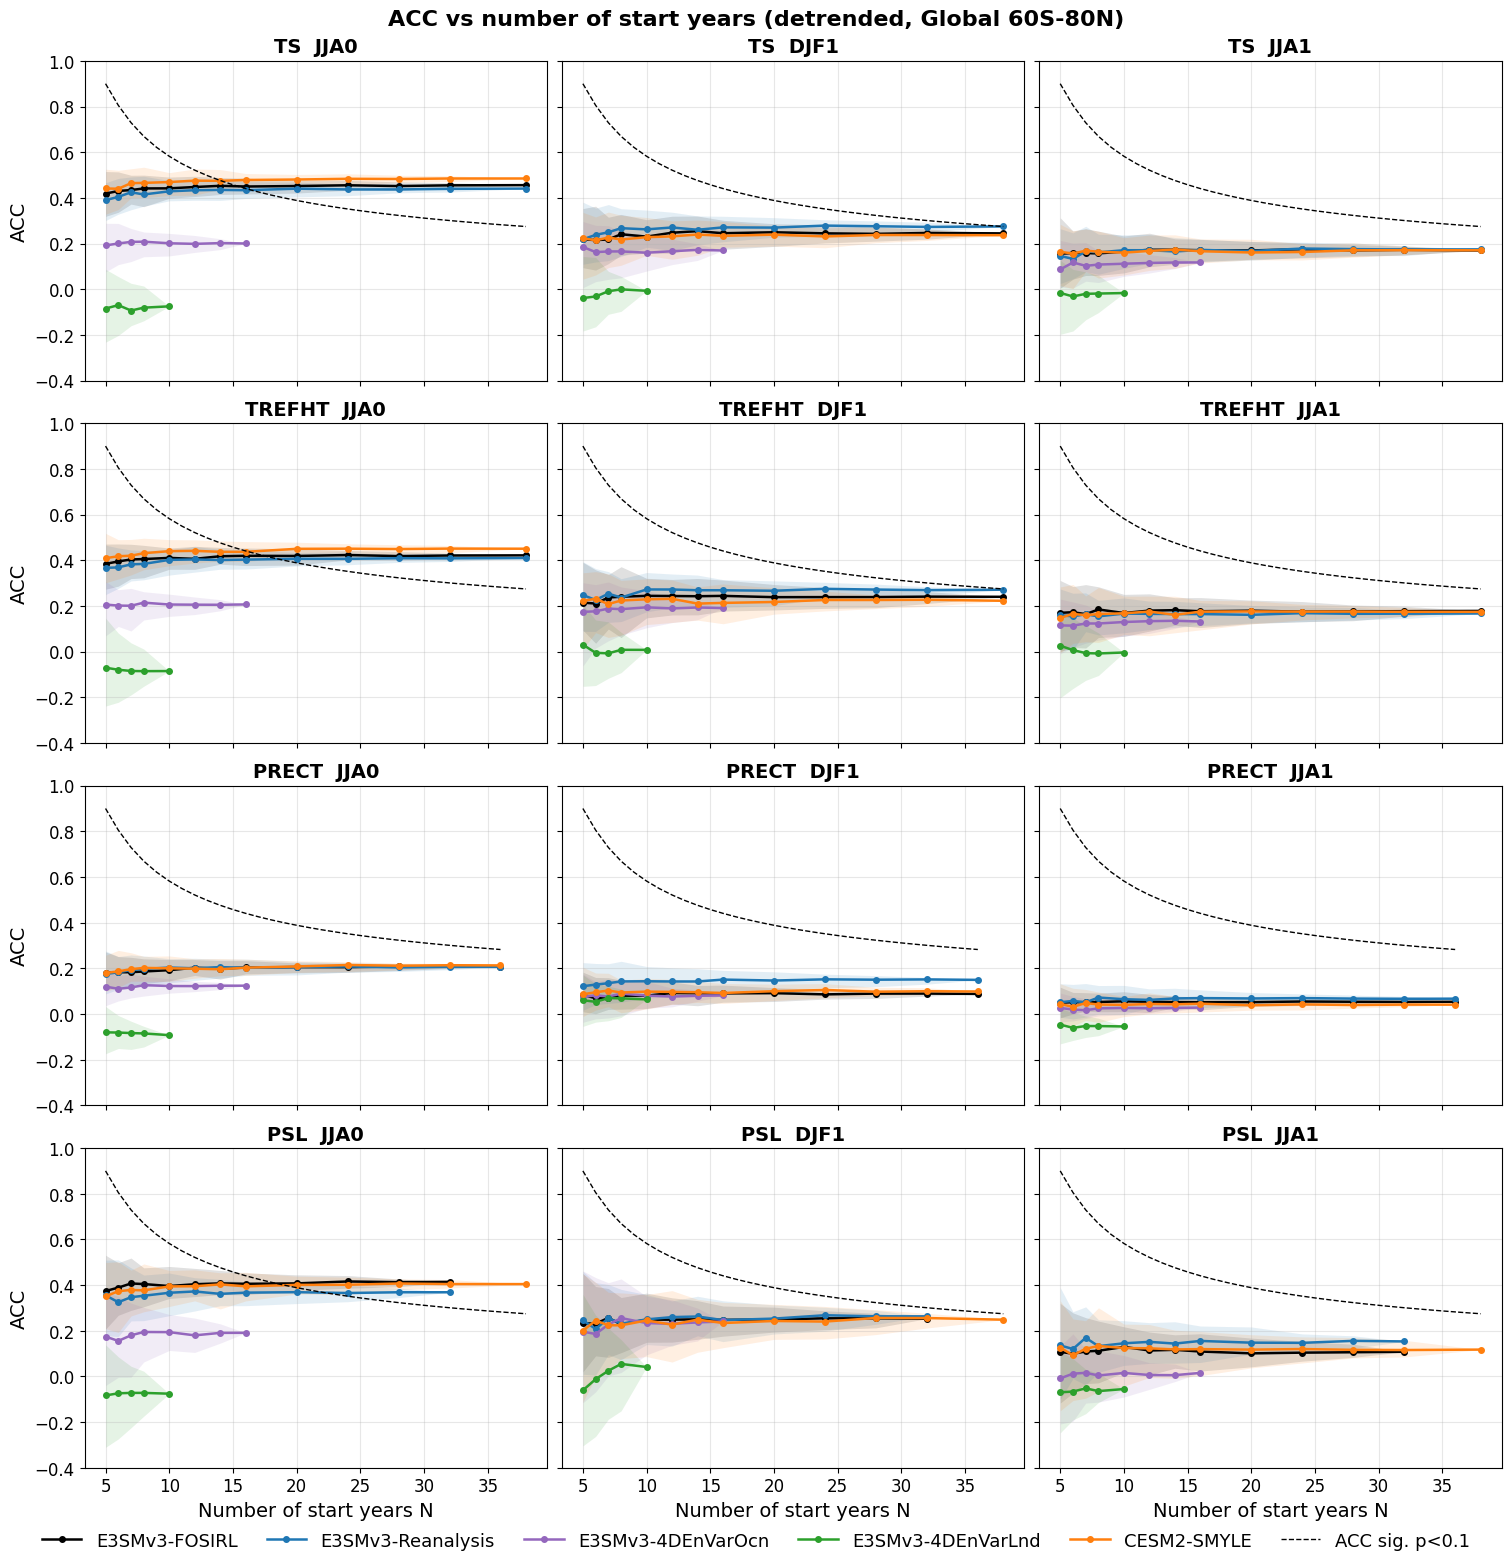

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_acc_sst.png


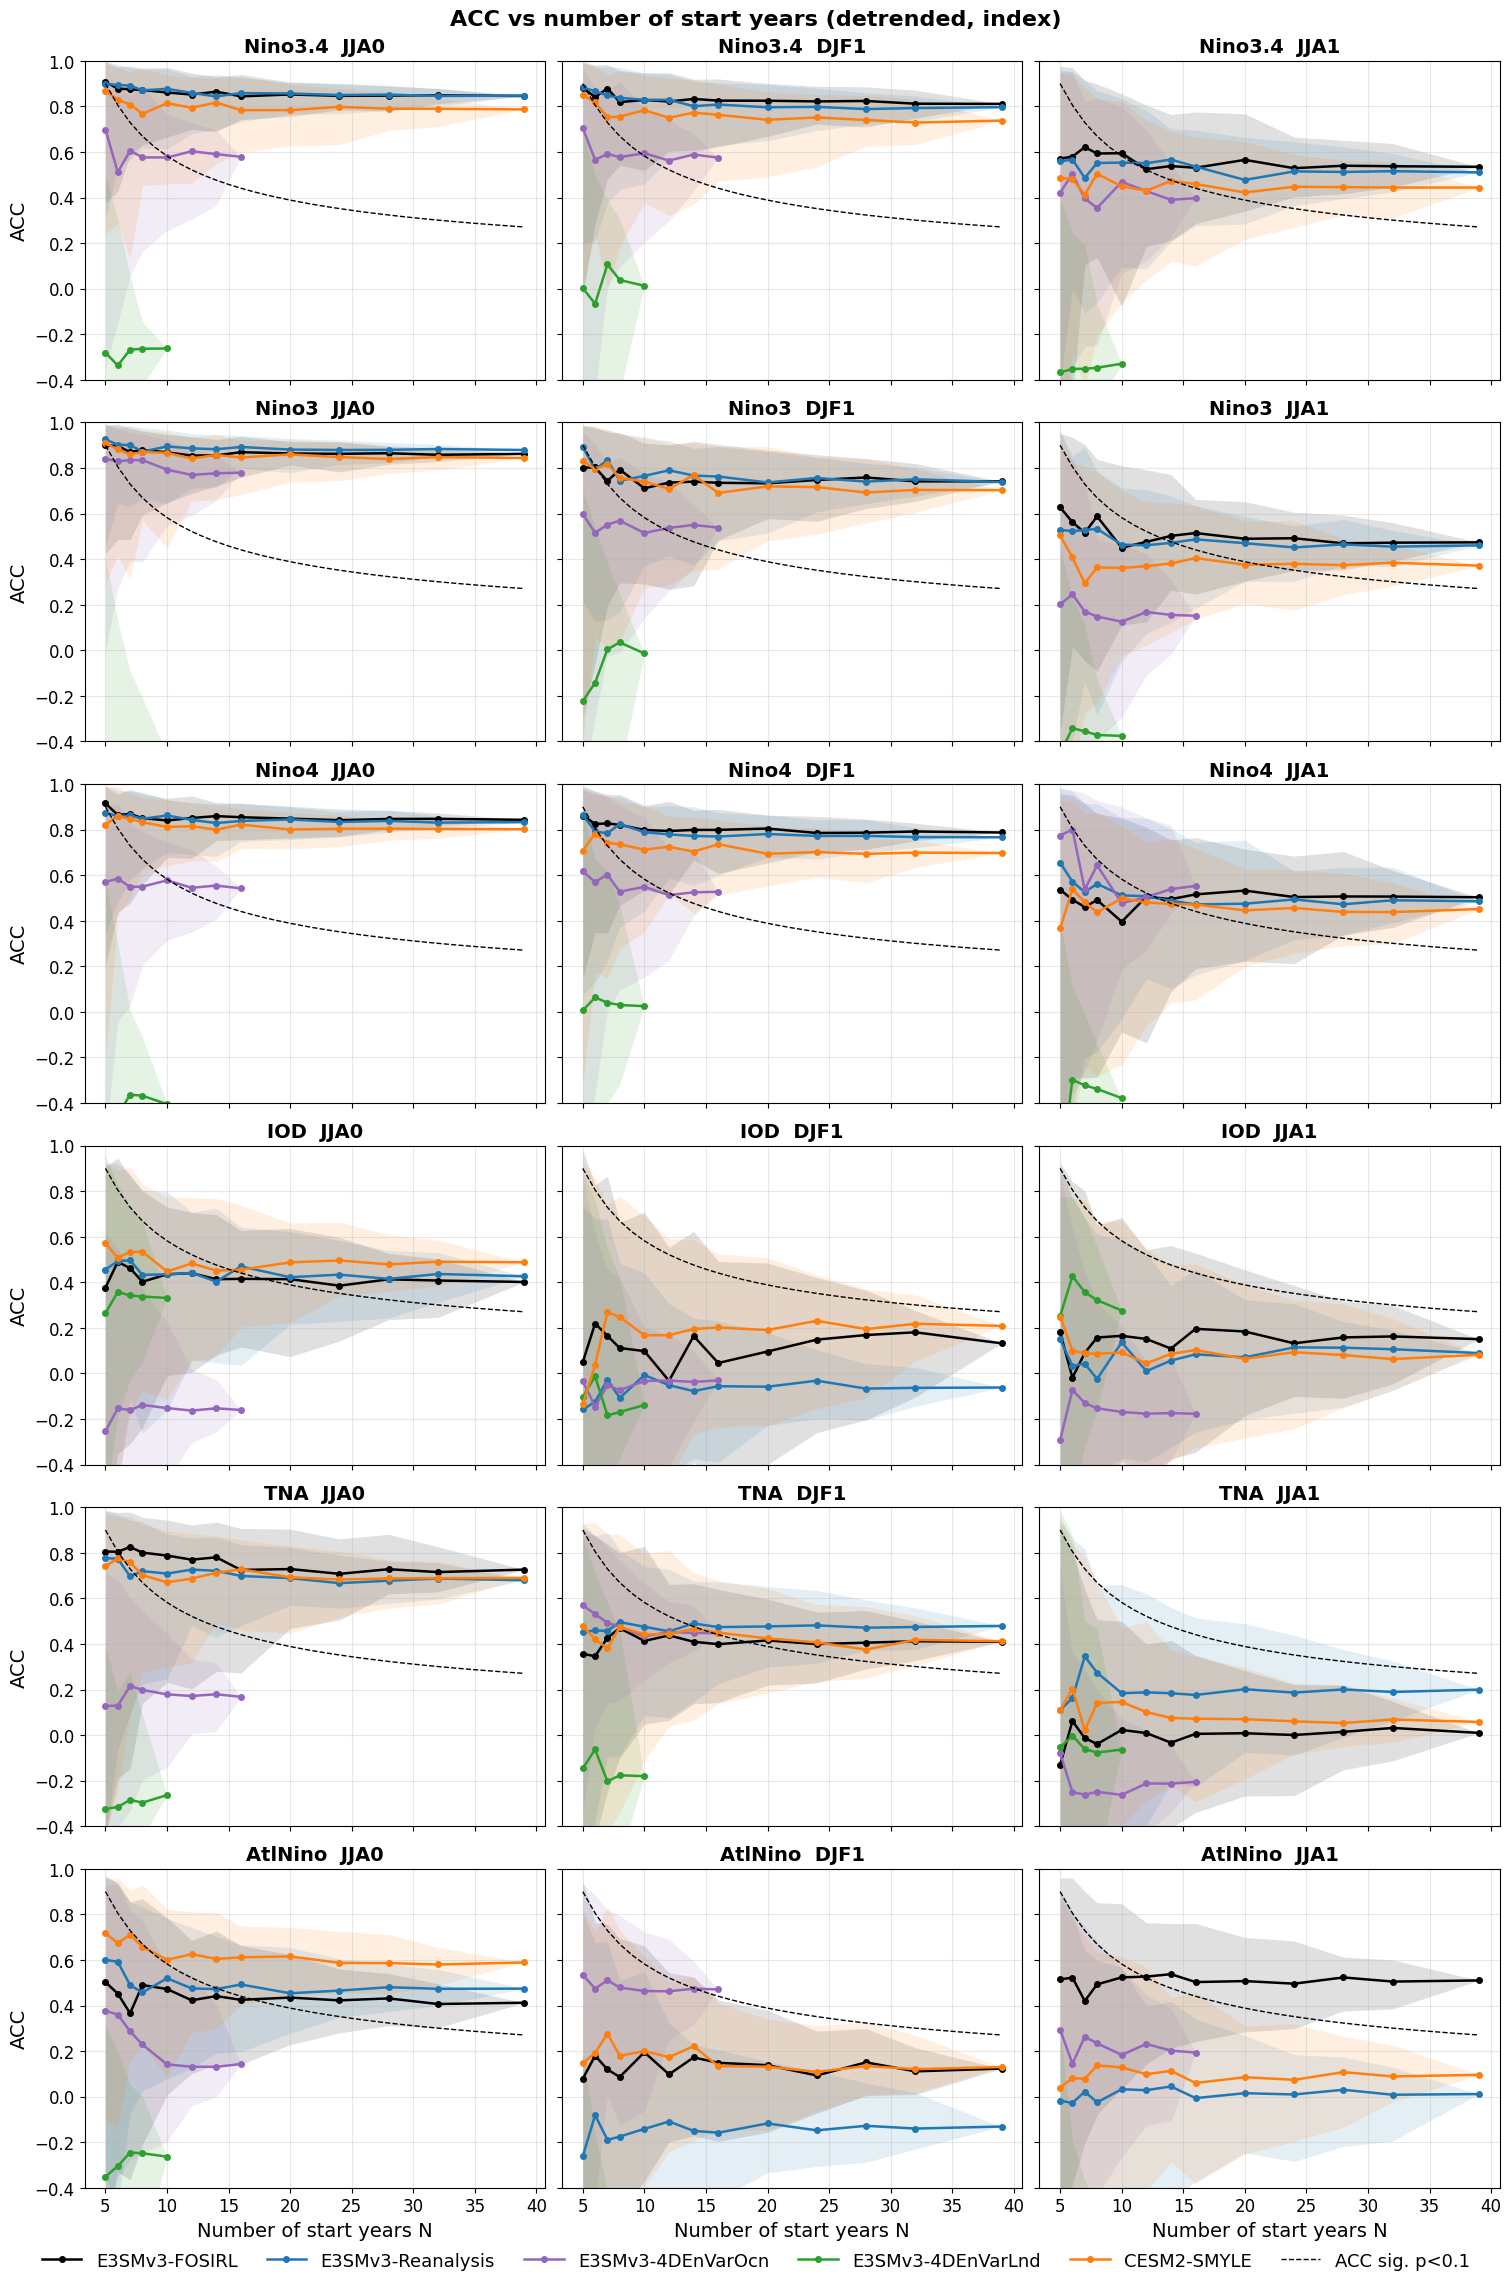

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_years_acc_lnd.png


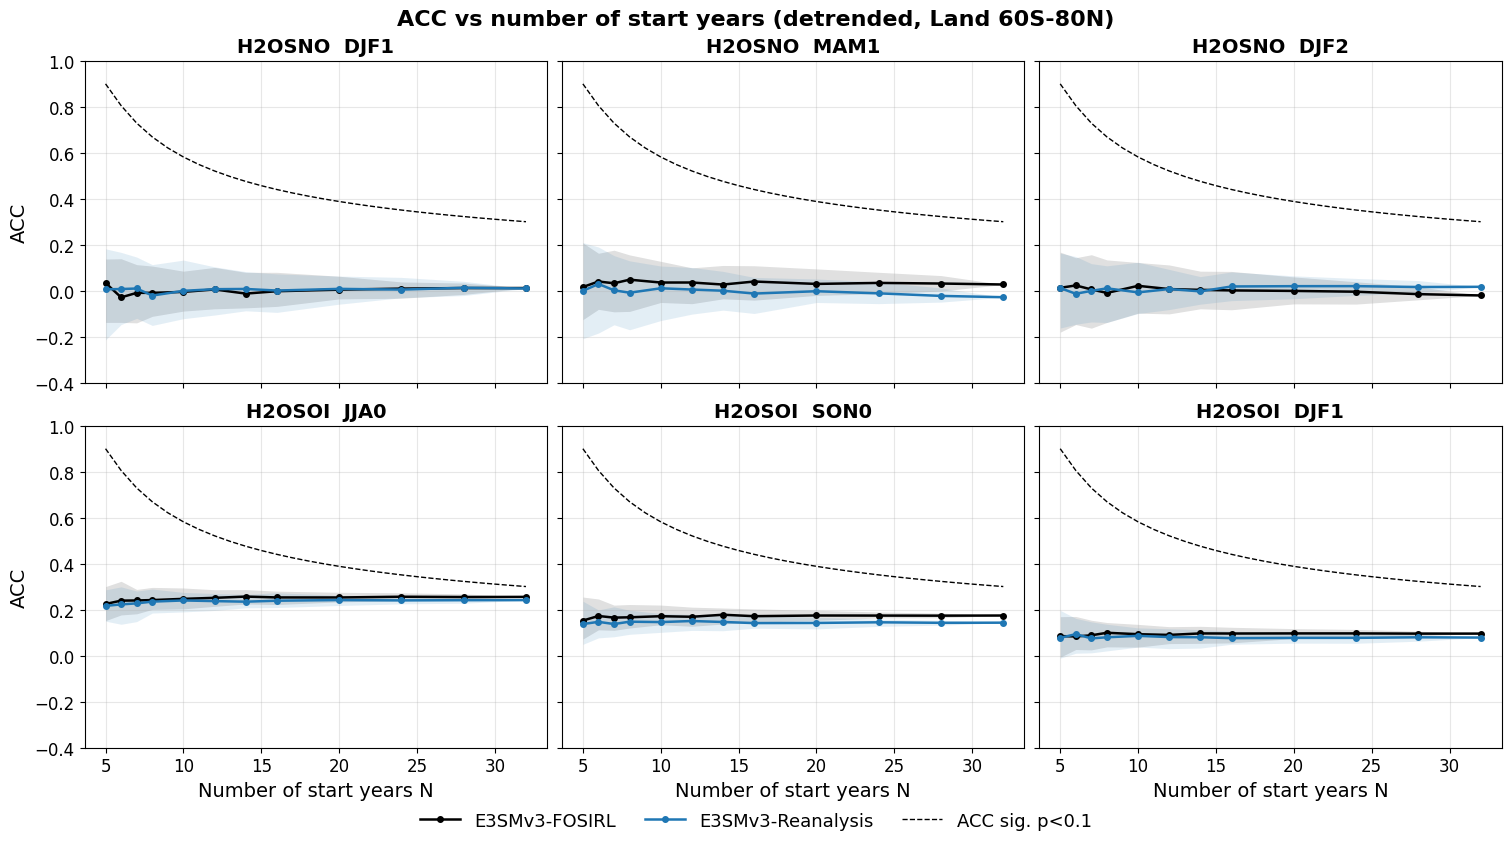

In [5]:
rows = []
for group, fields in DATA.items():
    for field, experiments in fields.items():
        for key, d in experiments.items():
            members = year_members(d["members"])
            fmean = members.mean("M")
            n_max = fmean.sizes["Y"]
            for n in sorted({n for n in N_GRID if n <= n_max} | {n_max}):
                weights = sss.random_subsets(n_max, n, N_DRAWS, rng)
                scores = sss.year_subset_scores(fmean, d["obs"], weights, detrend=DETREND, reduce=REDUCE[group])
                rows += summarize(scores, ["acc", "nrmse"], group=group, field=field, experiment=key, n_years=n)
        print(f"Part 1 done: {group} {field}")
part1 = pd.DataFrame(rows)
part1.to_csv(TABLE_DIR / f"sample_size_part1_start_years_init{INIT_MONTH:02d}.csv", index=False)


def acc_threshold(ax, group, field, lead, panel):
    n = np.arange(max(4, int(panel.n_years.min())), int(panel.n_years.max()) + 1)
    ax.plot(n, sss.acc_critical_value(n, SIG_LEVEL, detrend=DETREND), "k--", lw=1, label=f"ACC sig. p<{SIG_LEVEL:g}")


for group in DATA:
    plot_curves(part1, group, "n_years", "ACC", f"ACC vs number of start years ({'detrended' if DETREND else 'not detrended'}, {PLOT_REGION[group]})",
                f"fig_sample_size_years_acc_{group}.png", metric="acc", extra=acc_threshold, ylim=(-0.4, 1.0))

In [6]:
# How wide is the 5-95 % ACC range at a 4DEnVarLnd-sized record versus each experiment's full record?
n_ref = int(inventory.query("experiment == 'E3SM-4DEnVarLnd' and status == 'used'").n_years.max()
            if (inventory.experiment == "E3SM-4DEnVarLnd").any() else 10)
acc = part1[(part1.metric == "acc")].copy()
acc["range_90"] = acc.p95 - acc.p05
full = acc.loc[acc.groupby(["group", "field", "experiment", "region", "lead"]).n_years.idxmax()]
at_ref = acc[acc.n_years == n_ref]
spread = (at_ref.merge(full, on=["group", "field", "experiment", "region", "lead"], suffixes=(f"_N{n_ref}", "_full"))
          .assign(full_years=lambda t: t["n_years_full"]))
summary1 = (spread.groupby(["group", "field", "experiment"])
            [[f"median_N{n_ref}", f"range_90_N{n_ref}", "median_full", "range_90_full", "full_years"]].mean().round(2))
summary1.to_csv(TABLE_DIR / f"sample_size_part1_summary_N{n_ref}_init{INIT_MONTH:02d}.csv")
print(f"Lead- and region-averaged ACC median and 5-95 % width at N = {n_ref} vs the full record:")
summary1

Lead- and region-averaged ACC median and 5-95 % width at N = 10 vs the full record:


median_N10  range_90_N10  median_full  \
group field   experiment                                               
atm   PRECT   CESM-SMYLE             0.09          0.15         0.10   
              E3SM-4DEnVarLnd       -0.01          0.00        -0.01   
              E3SM-4DEnVarOcn        0.07          0.11         0.07   
              E3SM-FOSIRL            0.10          0.13         0.10   
              E3SM-Reanalysis        0.13          0.14         0.14   
      PSL     CESM-SMYLE             0.23          0.32         0.23   
              E3SM-4DEnVarLnd       -0.04          0.00        -0.04   
              E3SM-4DEnVarOcn        0.13          0.24         0.13   
              E3SM-FOSIRL            0.22          0.25         0.22   
              E3SM-Reanalysis        0.24          0.30         0.25   
      TREFHT  CESM-SMYLE             0.23          0.24         0.24   
              E3SM-4DEnVarLnd       -0.02          0.00        -0.02   
              E3SM-4DEnVarOcn        0.18          0.16         0.17   
              E3SM-FOSIRL            0.24          0.22         0.25   
              E3SM-Reanalysis        0.25          0.21         0.25   
      TS      CESM-SMYLE             0.23          0.22         0.24   
              E3SM-4DEnVarLnd       -0.03          0.00        -0.03   
              E3SM-4DEnVarOcn        0.16          0.16         0.16   
              E3SM-FOSIRL            0.23          0.20         0.24   
              E3SM-Reanalysis        0.25          0.19         0.26   
lnd   H2OSNO  E3SM-FOSIRL            0.02          0.19         0.01   
              E3SM-Reanalysis        0.00          0.24         0.00   
      H2OSOI  E3SM-FOSIRL            0.06          0.11         0.07   
              E3SM-Reanalysis        0.06          0.12         0.06   
sst   AtlNino CESM-SMYLE             0.21          1.04         0.20   
              E3SM-4DEnVarLnd       -0.56          0.00        -0.56   
              E3SM-4DEnVarOcn        0.27          0.76         0.28   
              E3SM-FOSIRL            0.31          0.98         0.28   
              E3SM-Reanalysis        0.07          0.92         0.05   
      IOD     CESM-SMYLE             0.16          0.95         0.17   
              E3SM-4DEnVarLnd        0.19          0.00         0.19   
              E3SM-4DEnVarOcn       -0.01          0.74        -0.02   
              E3SM-FOSIRL            0.24          0.92         0.22   
              E3SM-Reanalysis        0.25          0.92         0.23   
      Nino3   CESM-SMYLE             0.54          0.76         0.54   
              E3SM-4DEnVarLnd       -0.14          0.00        -0.14   
              E3SM-4DEnVarOcn        0.37          0.61         0.38   
              E3SM-FOSIRL            0.57          0.68         0.58   
              E3SM-Reanalysis        0.67          0.64         0.65   
      Nino3.4 CESM-SMYLE             0.63          0.73         0.61   
              E3SM-4DEnVarLnd       -0.11          0.00        -0.11   
              E3SM-4DEnVarOcn        0.45          0.59         0.43   
              E3SM-FOSIRL            0.69          0.65         0.66   
              E3SM-Reanalysis        0.73          0.59         0.69   
      Nino4   CESM-SMYLE             0.64          0.74         0.61   
              E3SM-4DEnVarLnd       -0.12          0.00        -0.12   
              E3SM-4DEnVarOcn        0.42          0.61         0.41   
              E3SM-FOSIRL            0.66          0.64         0.66   
              E3SM-Reanalysis        0.70          0.55         0.68   
      TNA     CESM-SMYLE             0.31          0.90         0.29   
              E3SM-4DEnVarLnd       -0.16          0.00        -0.16   
              E3SM-4DEnVarOcn        0.18          0.64         0.18   
              E3SM-FOSIRL            0.36          0.85         0.34   
              E3SM-Reanalysis        0.40          0.87         0.39   

## Part 2 — skill vs. ensemble size

All start years of each experiment are scored with ensemble means of M randomly chosen members
(M = 1 … all). The dotted line is the fit ACC(M) = ACC∞ / √(1 + k/M) to the median curve (k is the
noise-to-signal variance ratio), extended to the right edge; the table lists the fitted ACC∞.

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


... (292 outputs left out)

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Part 2 done: lnd H2OSOI
Part 2 done: lnd TWS


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_members_acc_atm.png


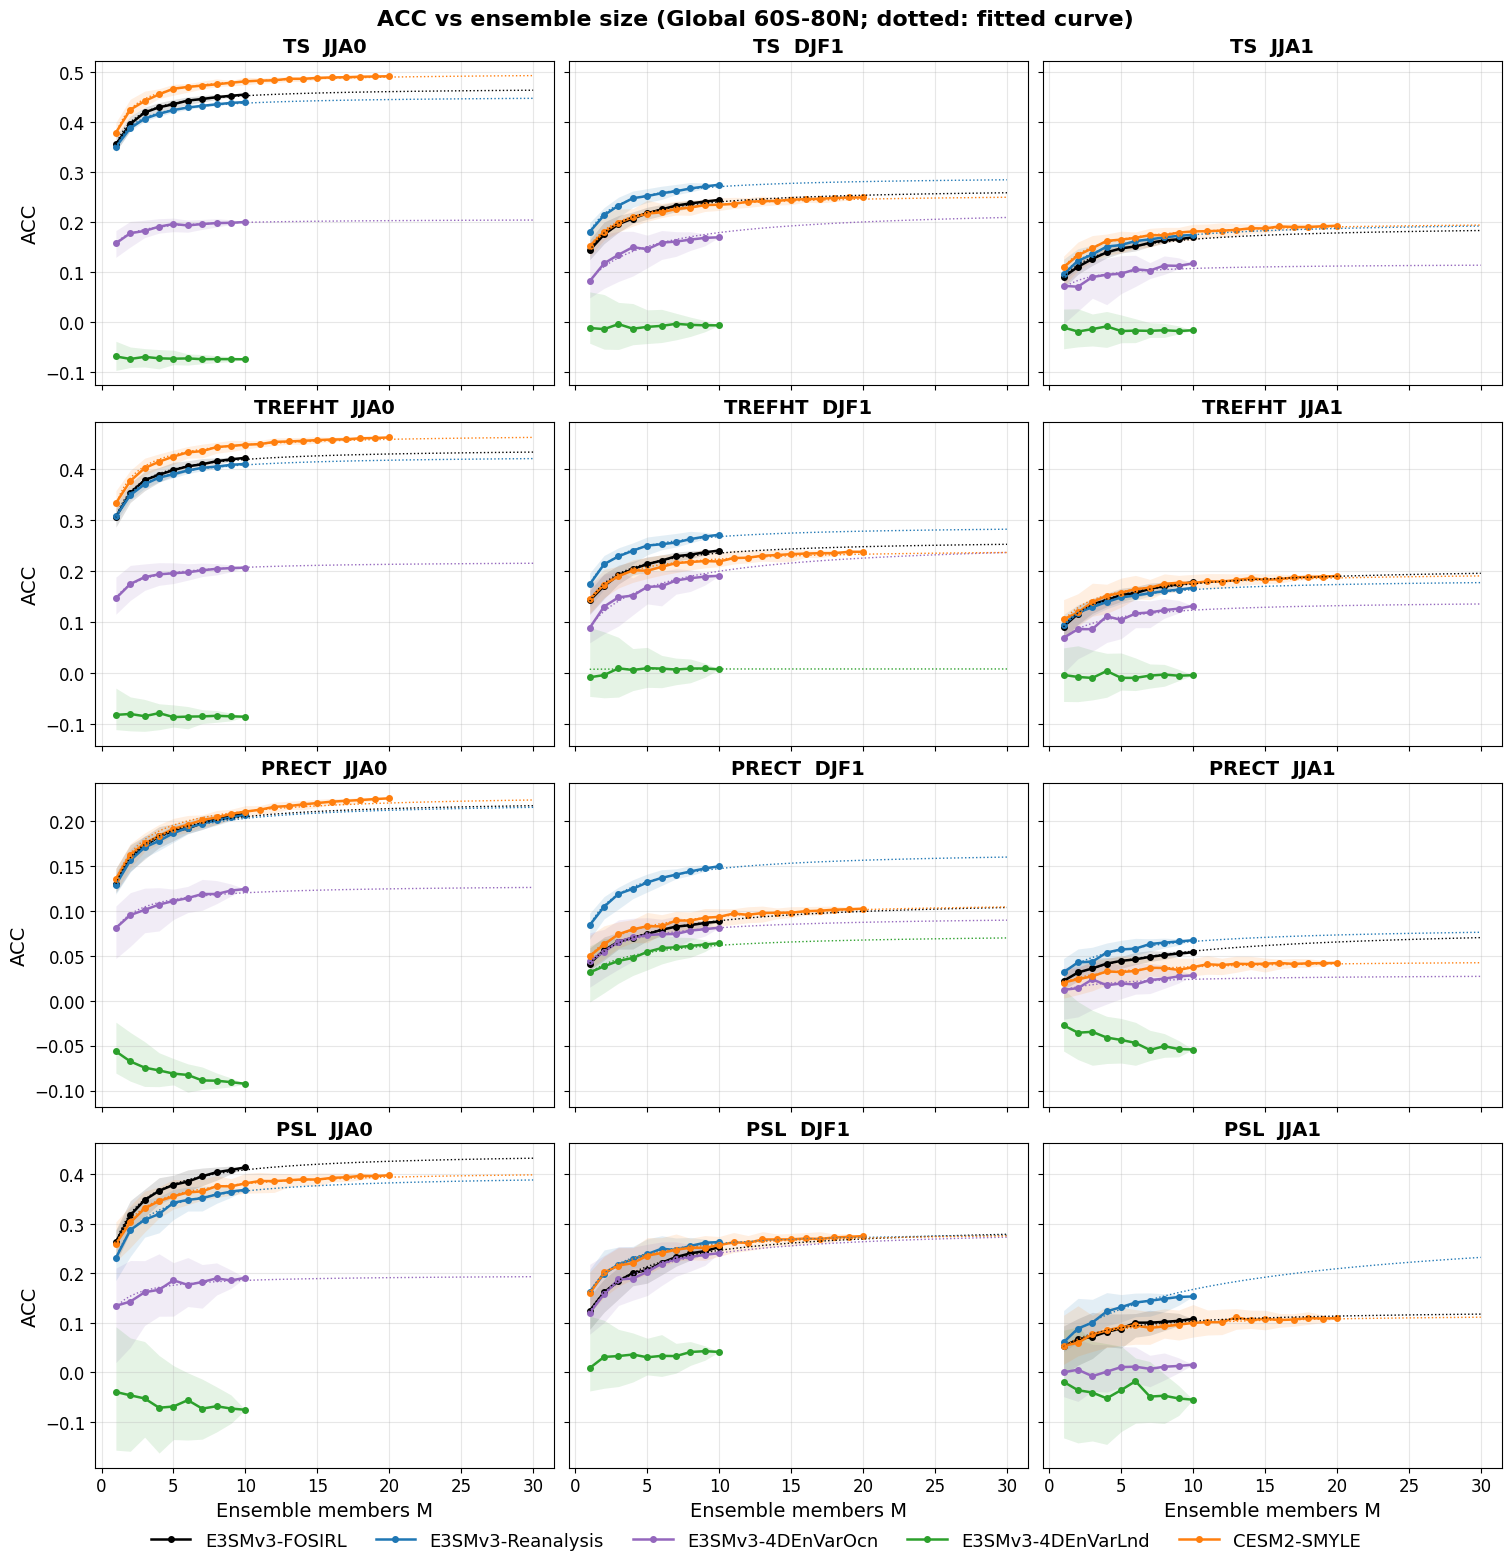

/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:274: RuntimeWarning: invalid value encountered in sqrt
  return acc_inf / np.sqrt(1.0 + ratio / m)


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_members_acc_sst.png


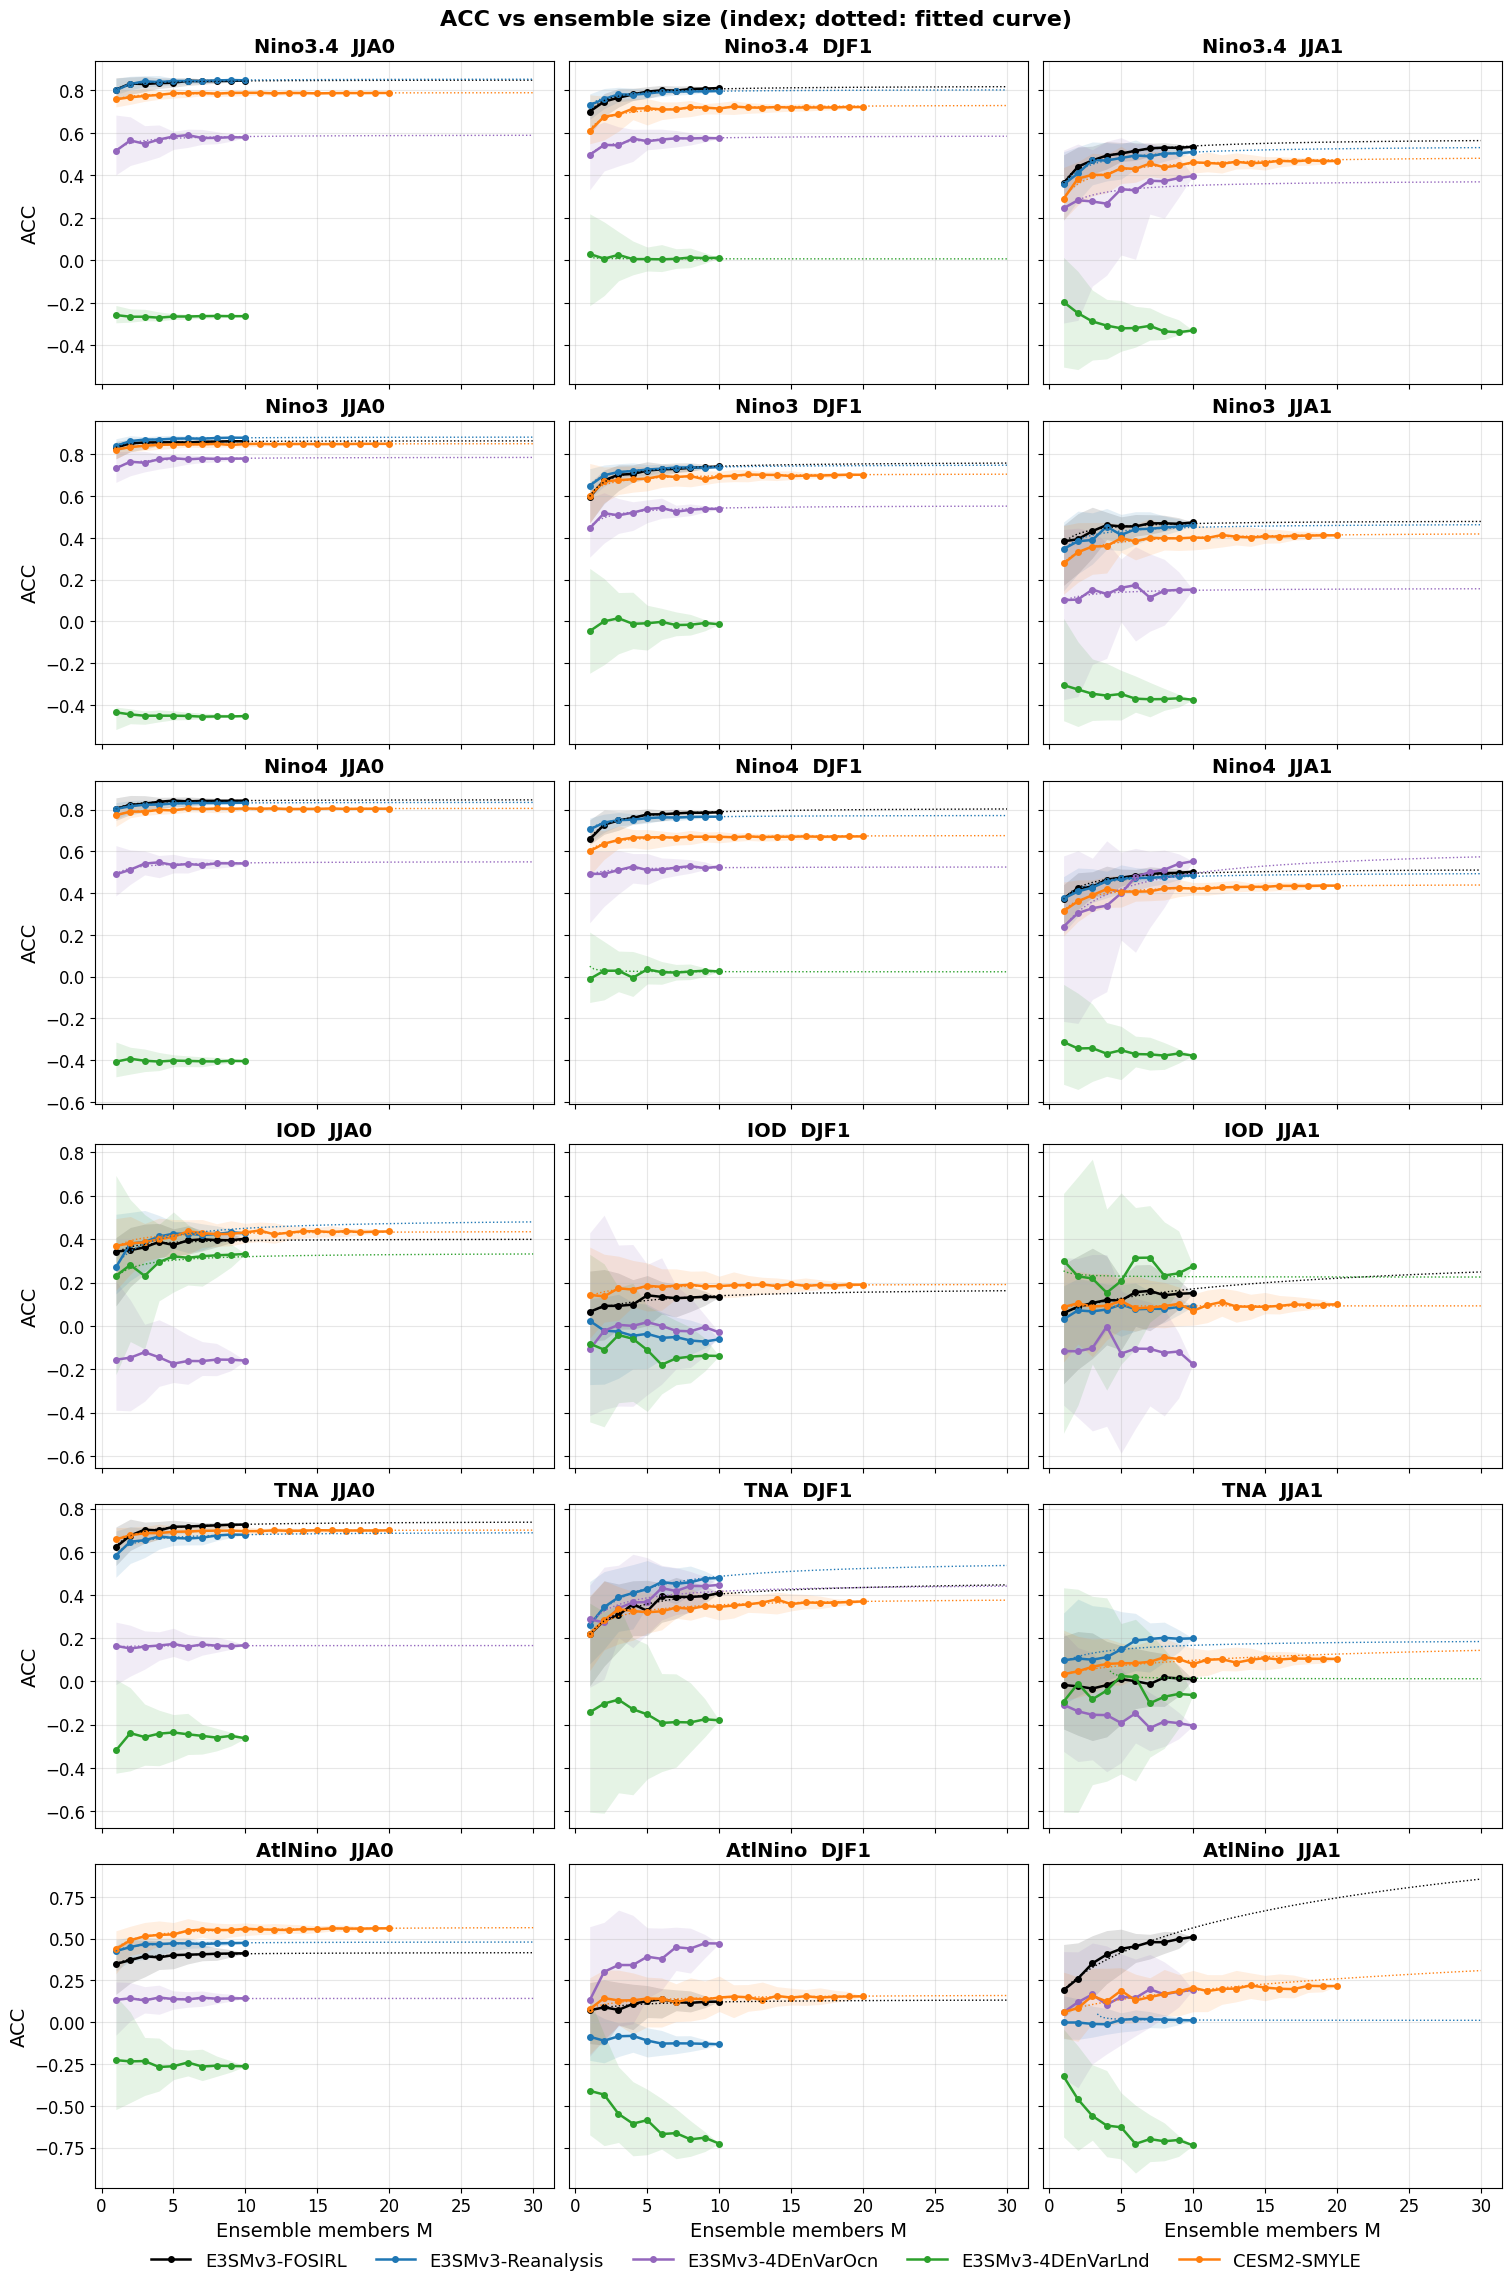

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_members_acc_lnd.png


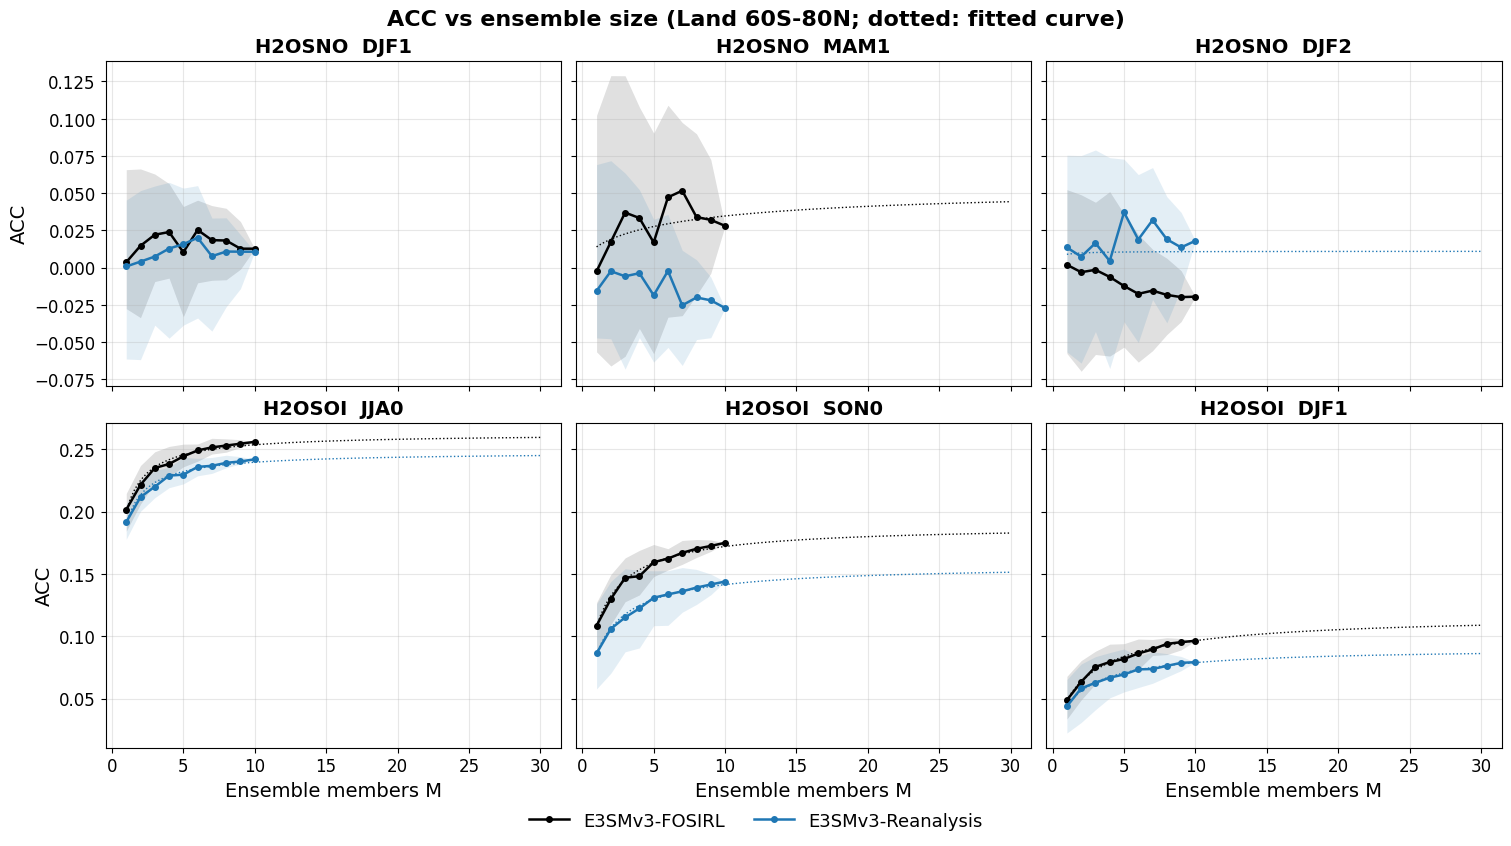

lead                              0     1     2     3     4     5     6
group field   experiment                                               
atm   PRECT   CESM-SMYLE       0.19  0.14  0.09  0.05  0.03  0.03  0.04
              E3SM-4DEnVarLnd   NaN  0.21  0.10   NaN   NaN  0.01  0.05
              E3SM-4DEnVarOcn  0.13  0.06  0.08  0.10  0.03  0.01  0.03
              E3SM-FOSIRL      0.19  0.16  0.09  0.05  0.11  0.00  0.08
              E3SM-Reanalysis  0.21  0.13  0.14  0.12  0.15  0.05  0.13
      PSL     CESM-SMYLE       0.39  0.30  0.23  0.19  0.13  0.08  0.11
              E3SM-4DEnVarLnd   NaN   NaN  0.11  0.02   NaN   NaN  0.03
              E3SM-4DEnVarOcn  0.16  0.13  0.21  0.20   NaN   NaN  0.07
              E3SM-FOSIRL      0.44  0.24  0.46  0.20  0.14  0.05  0.18
              E3SM-Reanalysis  0.39  0.22  0.20  0.20  0.23  0.12  0.20
      TREFHT  CESM-SMYLE       0.38  0.26  0.22  0.17  0.17  0.12  0.15
              E3SM-4DEnVarLnd   NaN   NaN  0.03   NaN   NaN  0.02  0.23
              E3SM-4DEnVarOcn  0.16  0.17  0.29  0.14  0.20  0.25  0.41
              E3SM-FOSIRL      0.35  0.27  0.18  0.40  0.23  0.11  0.15
              E3SM-Reanalysis  0.34  0.22  0.21  0.19  0.19  0.08  0.16
      TS      CESM-SMYLE       0.39  0.27  0.23  0.17  0.16  0.11  0.13
              E3SM-4DEnVarLnd   NaN   NaN  0.06   NaN   NaN  0.00  0.14
              E3SM-4DEnVarOcn  0.15  0.17  0.29  0.13  0.20  0.10  0.21
              E3SM-FOSIRL      0.37  0.29  0.18  0.24  0.22  0.17  0.13
              E3SM-Reanalysis  0.35  0.23  0.22  0.18  0.18  0.09  0.16
lnd   H2OSNO  E3SM-FOSIRL       NaN  0.05   NaN   NaN   NaN   NaN   NaN
              E3SM-Reanalysis   NaN   NaN  0.01   NaN   NaN   NaN   NaN
      H2OSOI  E3SM-FOSIRL      0.26  0.19  0.12  0.07  0.03   NaN   NaN
              E3SM-Reanalysis  0.25  0.16  0.09  0.07  0.01  0.00  0.04
sst   AtlNino CESM-SMYLE       0.57  0.34  0.17   NaN  0.76  0.61  0.38
              E3SM-4DEnVarOcn  0.14  0.13   NaN  0.60   NaN  0.17   NaN
              E3SM-FOSIRL      0.42  0.23  0.14  0.08  1.45  0.62  0.36
              E3SM-Reanalysis  0.48  0.15   NaN   NaN  0.01   NaN  0.10
      IOD     CESM-SMYLE       0.44  0.48  0.19   NaN  0.09  0.15   NaN
              E3SM-4DEnVarLnd  0.34  0.18   NaN   NaN  0.22   NaN  0.06
              E3SM-4DEnVarOcn   NaN   NaN   NaN   NaN   NaN   NaN  0.05
              E3SM-FOSIRL      0.40  0.61  0.18  0.00  0.38  0.71   NaN
              E3SM-Reanalysis  0.50  0.46   NaN  0.01   NaN  0.32  1.32
      Nino3   CESM-SMYLE       0.85  0.71  0.71  0.47  0.43  0.43  0.44
              E3SM-4DEnVarLnd   NaN  0.03   NaN   NaN   NaN  0.06   NaN
              E3SM-4DEnVarOcn  0.79  0.46  0.56  0.62  0.16  0.03  0.09
              E3SM-FOSIRL      0.87  0.78  0.77  0.39  0.48  0.48  0.47
              E3SM-Reanalysis  0.88  0.78  0.75  0.52  0.47  0.68  0.80
      Nino3.4 CESM-SMYLE       0.79  0.72  0.73  0.63  0.49  0.50  0.50
              E3SM-4DEnVarLnd   NaN  0.11  0.01   NaN   NaN  0.05   NaN
              E3SM-4DEnVarOcn  0.59  0.52  0.59  0.75  0.38  0.03   NaN
              E3SM-FOSIRL      0.85  0.83  0.82  0.68  0.58  0.52  0.52
              E3SM-Reanalysis  0.85  0.82  0.81  0.62  0.54  0.69  0.72
      Nino4   CESM-SMYLE       0.81  0.72  0.68  0.62  0.45  0.49  0.52
              E3SM-4DEnVarLnd   NaN  0.05  0.02   NaN   NaN  0.02   NaN
              E3SM-4DEnVarOcn  0.55  0.51  0.53  0.77  0.63   NaN   NaN
              E3SM-FOSIRL      0.85  0.82  0.81  0.74  0.52  0.49  0.49
              E3SM-Reanalysis  0.84  0.80  0.77  0.69  0.50  0.63  0.66
      TNA     CESM-SMYLE       0.70  0.48  0.39  0.18  0.22  0.22  0.28
              E3SM-4DEnVarLnd   NaN   NaN   NaN  0.01  0.01   NaN   NaN
              E3SM-4DEnVarOcn  0.17  0.33  0.46  0.23   NaN  0.25  0.06
              E3SM-FOSIRL      0.74  0.59  0.47   NaN   NaN   NaN  4.62
              E3SM-Reanalysis  0.69  0.49  0.57  0.58  0.20  0.37  0.16

In [7]:
rows, fits = [], []
for group, fields in DATA.items():
    for field, experiments in fields.items():
        for key, d in experiments.items():
            members = d["members"]
            for m in range(1, members.sizes["M"] + 1):
                weights = sss.random_subsets(members.sizes["M"], m, N_DRAWS // 2, rng)
                scores = sss.member_subset_scores(members, d["obs"], weights, detrend=DETREND, reduce=REDUCE[group])
                rows += summarize(scores, ["acc", "nrmse"], group=group, field=field, experiment=key, members=m)
        print(f"Part 2 done: {group} {field}")
part2 = pd.DataFrame(rows)
for (group, field, key, region, lead), curve in part2[part2.metric == "acc"].groupby(
        ["group", "field", "experiment", "region", "lead"]):
    acc_inf, ratio = sss.fit_member_curve(curve.members, curve["median"])
    fits.append(dict(group=group, field=field, experiment=key, region=region, lead=lead,
                     members=int(curve.members.max()), acc_full=float(curve["median"].iloc[-1]),
                     acc_inf=acc_inf, noise_to_signal=ratio))
fits = pd.DataFrame(fits)
part2.to_csv(TABLE_DIR / f"sample_size_part2_members_init{INIT_MONTH:02d}.csv", index=False)
fits.to_csv(TABLE_DIR / f"sample_size_part2_acc_inf_init{INIT_MONTH:02d}.csv", index=False)


def member_fit(ax, group, field, lead, panel):
    m = np.linspace(1, max(int(panel.members.max()), 20) * 1.5, 100)
    for key, info in EXPERIMENTS.items():
        f = fits[(fits.group == group) & (fits.field == field) & (fits.experiment == key)
                 & (fits.region == PLOT_REGION[group]) & (fits.lead == lead)]
        if not f.empty and np.isfinite(f.acc_inf.iloc[0]):
            ax.plot(m, sss.member_curve(f.acc_inf.iloc[0], f.noise_to_signal.iloc[0], m), ":", color=info["color"], lw=1)


for group in DATA:
    plot_curves(part2, group, "members", "ACC", f"ACC vs ensemble size ({PLOT_REGION[group]}; dotted: fitted curve)",
                f"fig_sample_size_members_acc_{group}.png", metric="acc", extra=member_fit)

(fits[fits.region.isin(PLOT_REGION.values())]
 .pivot_table(index=["group", "field", "experiment"], columns="lead", values="acc_inf").round(2))

## Part 3 — start years needed for the lead-time climatology

For each experiment the drift climatology (and the paired observed climatology) is built from K random
start years and removed from every year, then all years are scored without detrending. Shown is RMSE
relative to its large-K value: in-sample (one climatology for all years; reference K = N, the workflow)
and cross-validated (each year's climatology excludes that year; reference K = N − 1, leave-one-out).
A second figure shows the RMS
climatology error in units of the interannual standard deviation, with the 1/√K sampling-error guide.
Dashed grey: the sampling-only expectation for independent, trend-free errors, √((1 + 1/K − 2/N)/(1 − 1/N))
in-sample and √((1 + 1/K)/(1 + 1/(N − 1))) cross-validated; e.g. a 5 % RMSE tolerance needs K ≈ 10
(√(1 + 1/K) ≤ 1.05). Departures from it come from trends and autocorrelation in the errors.
The table gives the smallest K from which the median RMSE stays within `CLIM_TOLERANCE` (and the 95th
percentile within twice that) of the full-record value.

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


... (4,921 outputs left out)

/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/pytho

Part 3 done: lnd H2OSOI
Part 3 done: lnd TWS


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_in-sample_atm.png


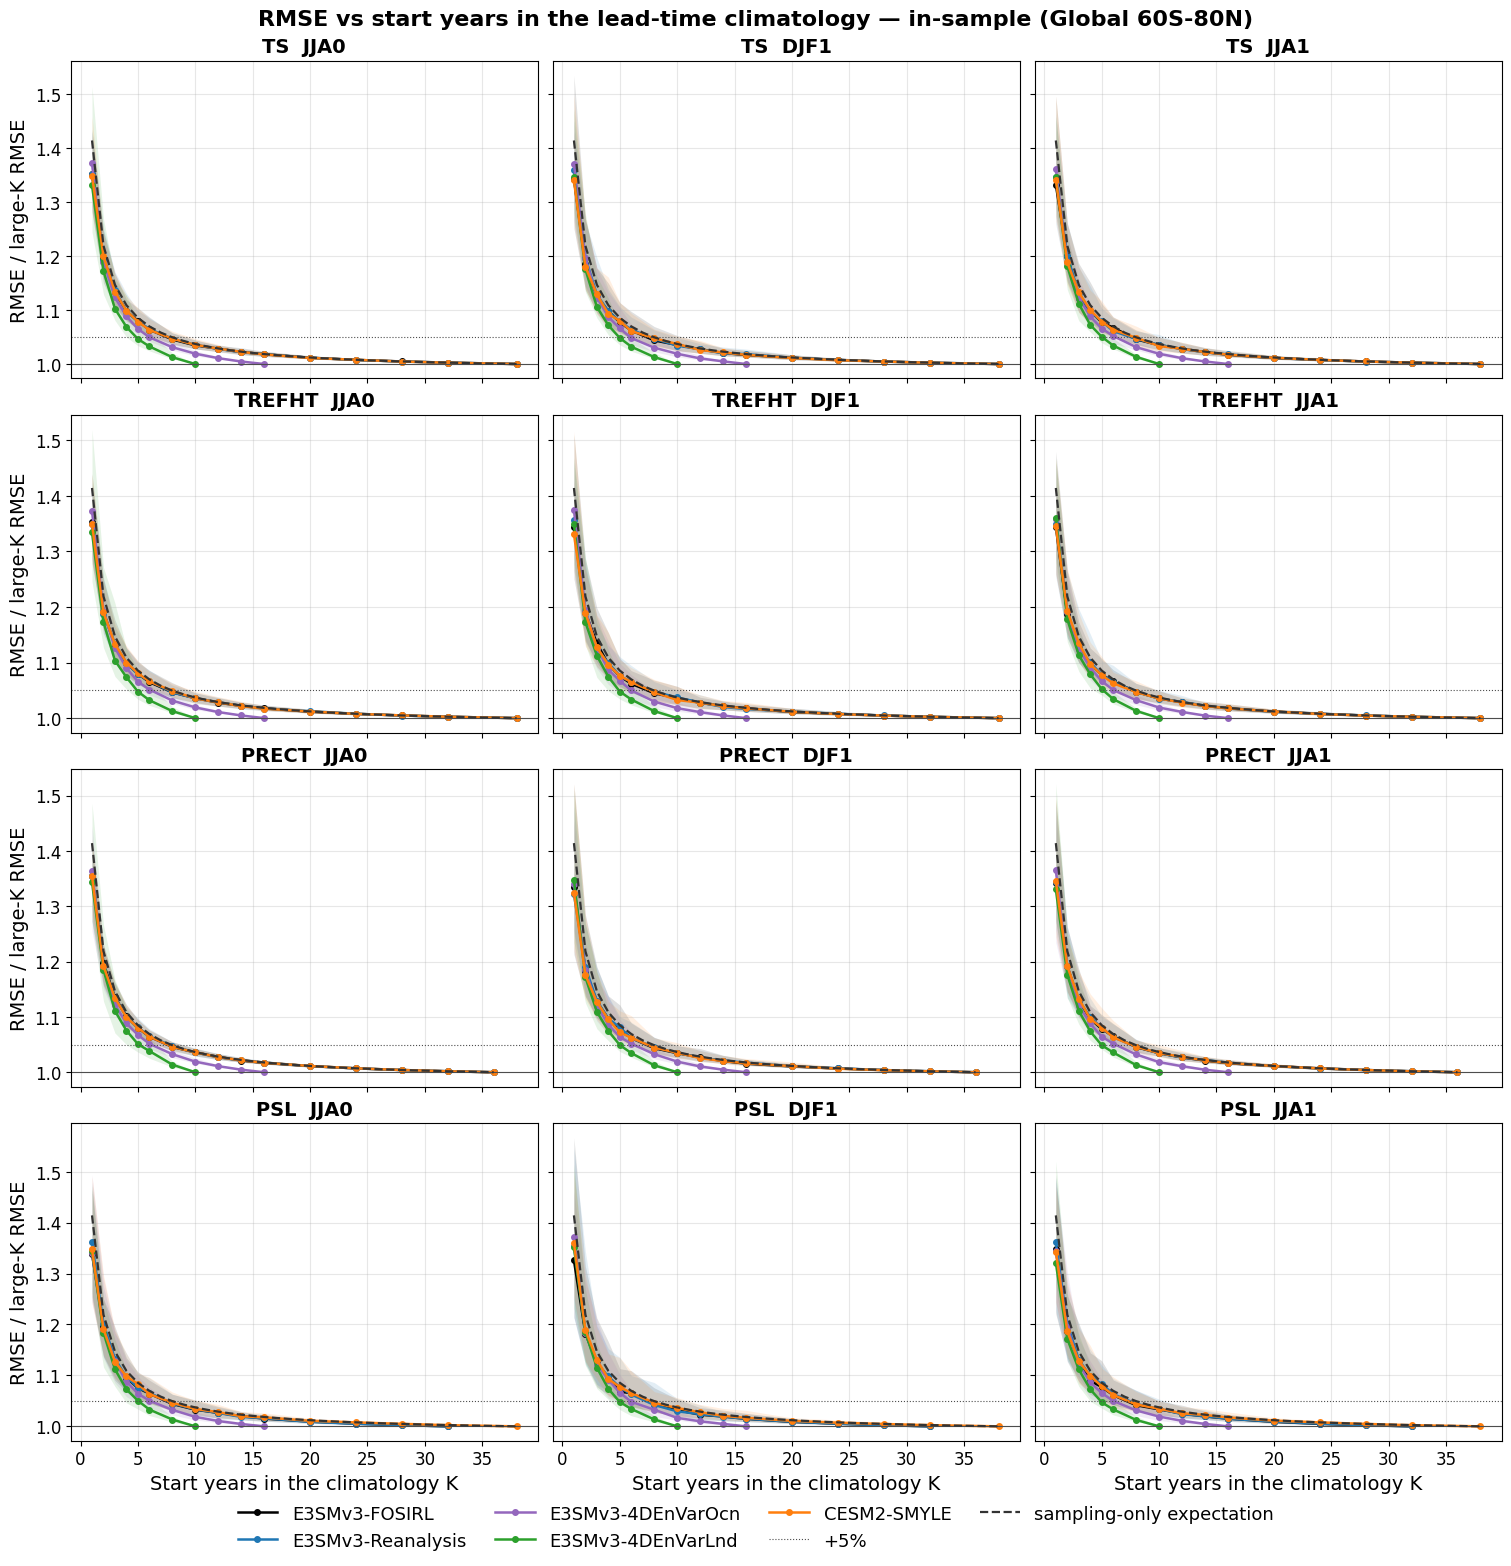

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_cross-validated_atm.png


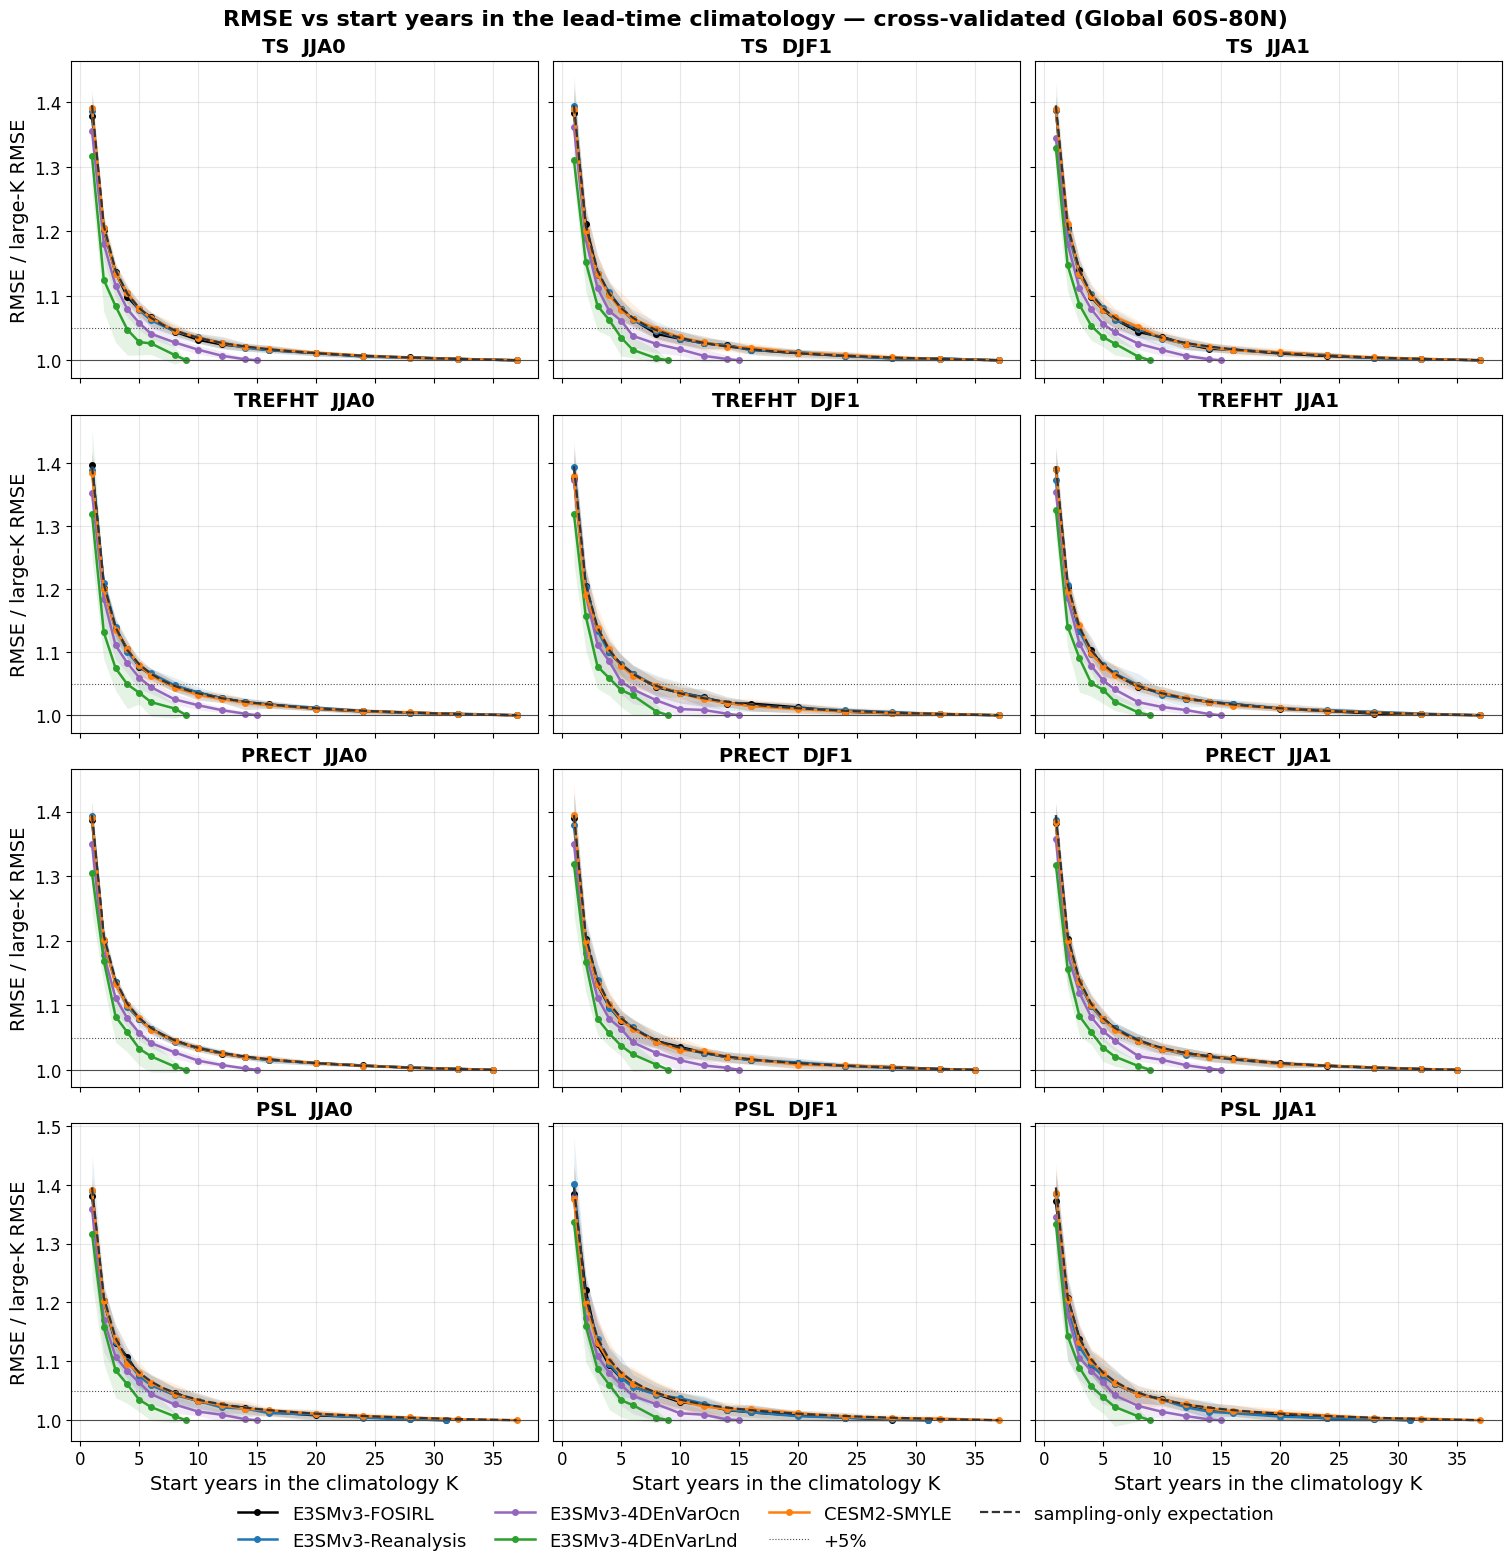

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_error_atm.png


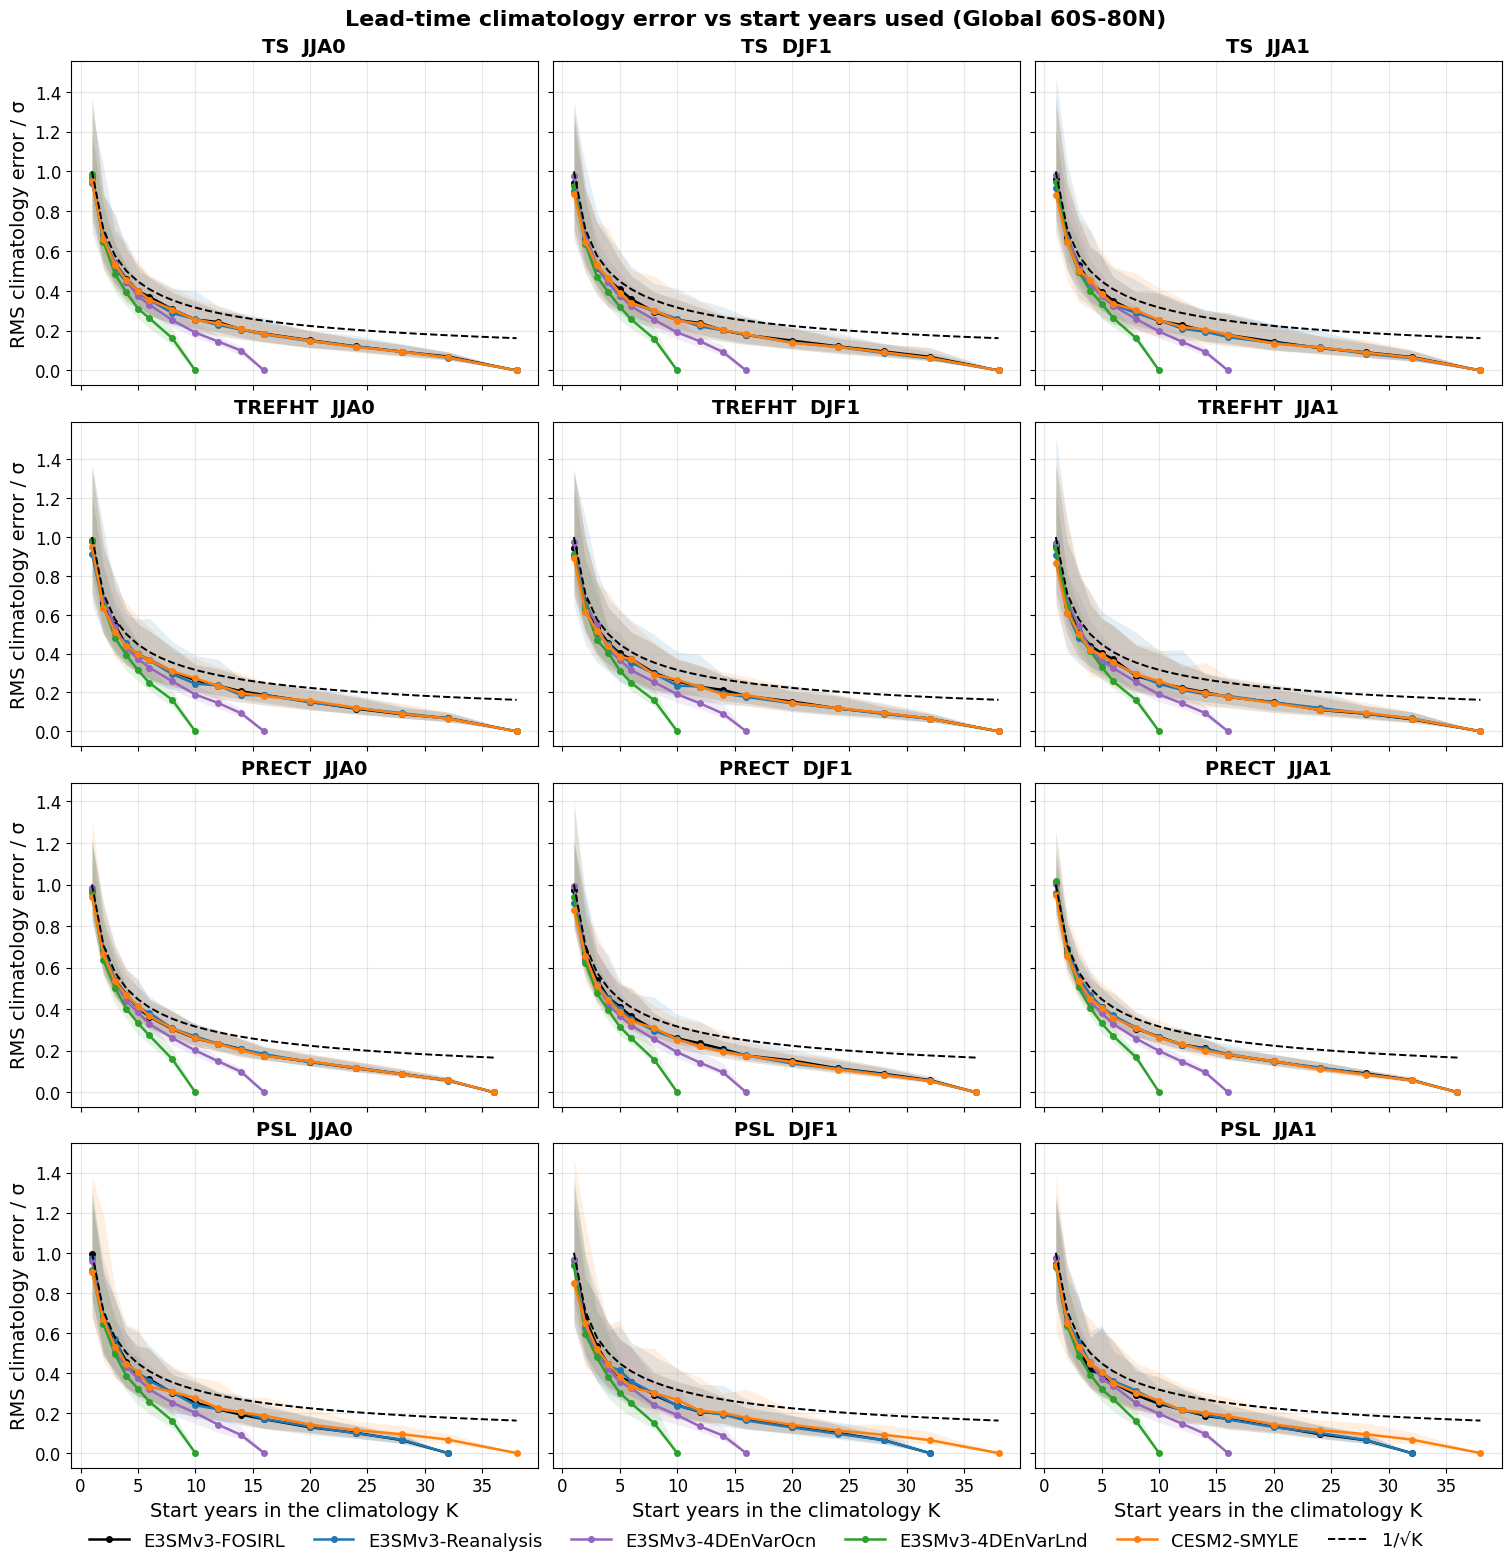

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_in-sample_sst.png


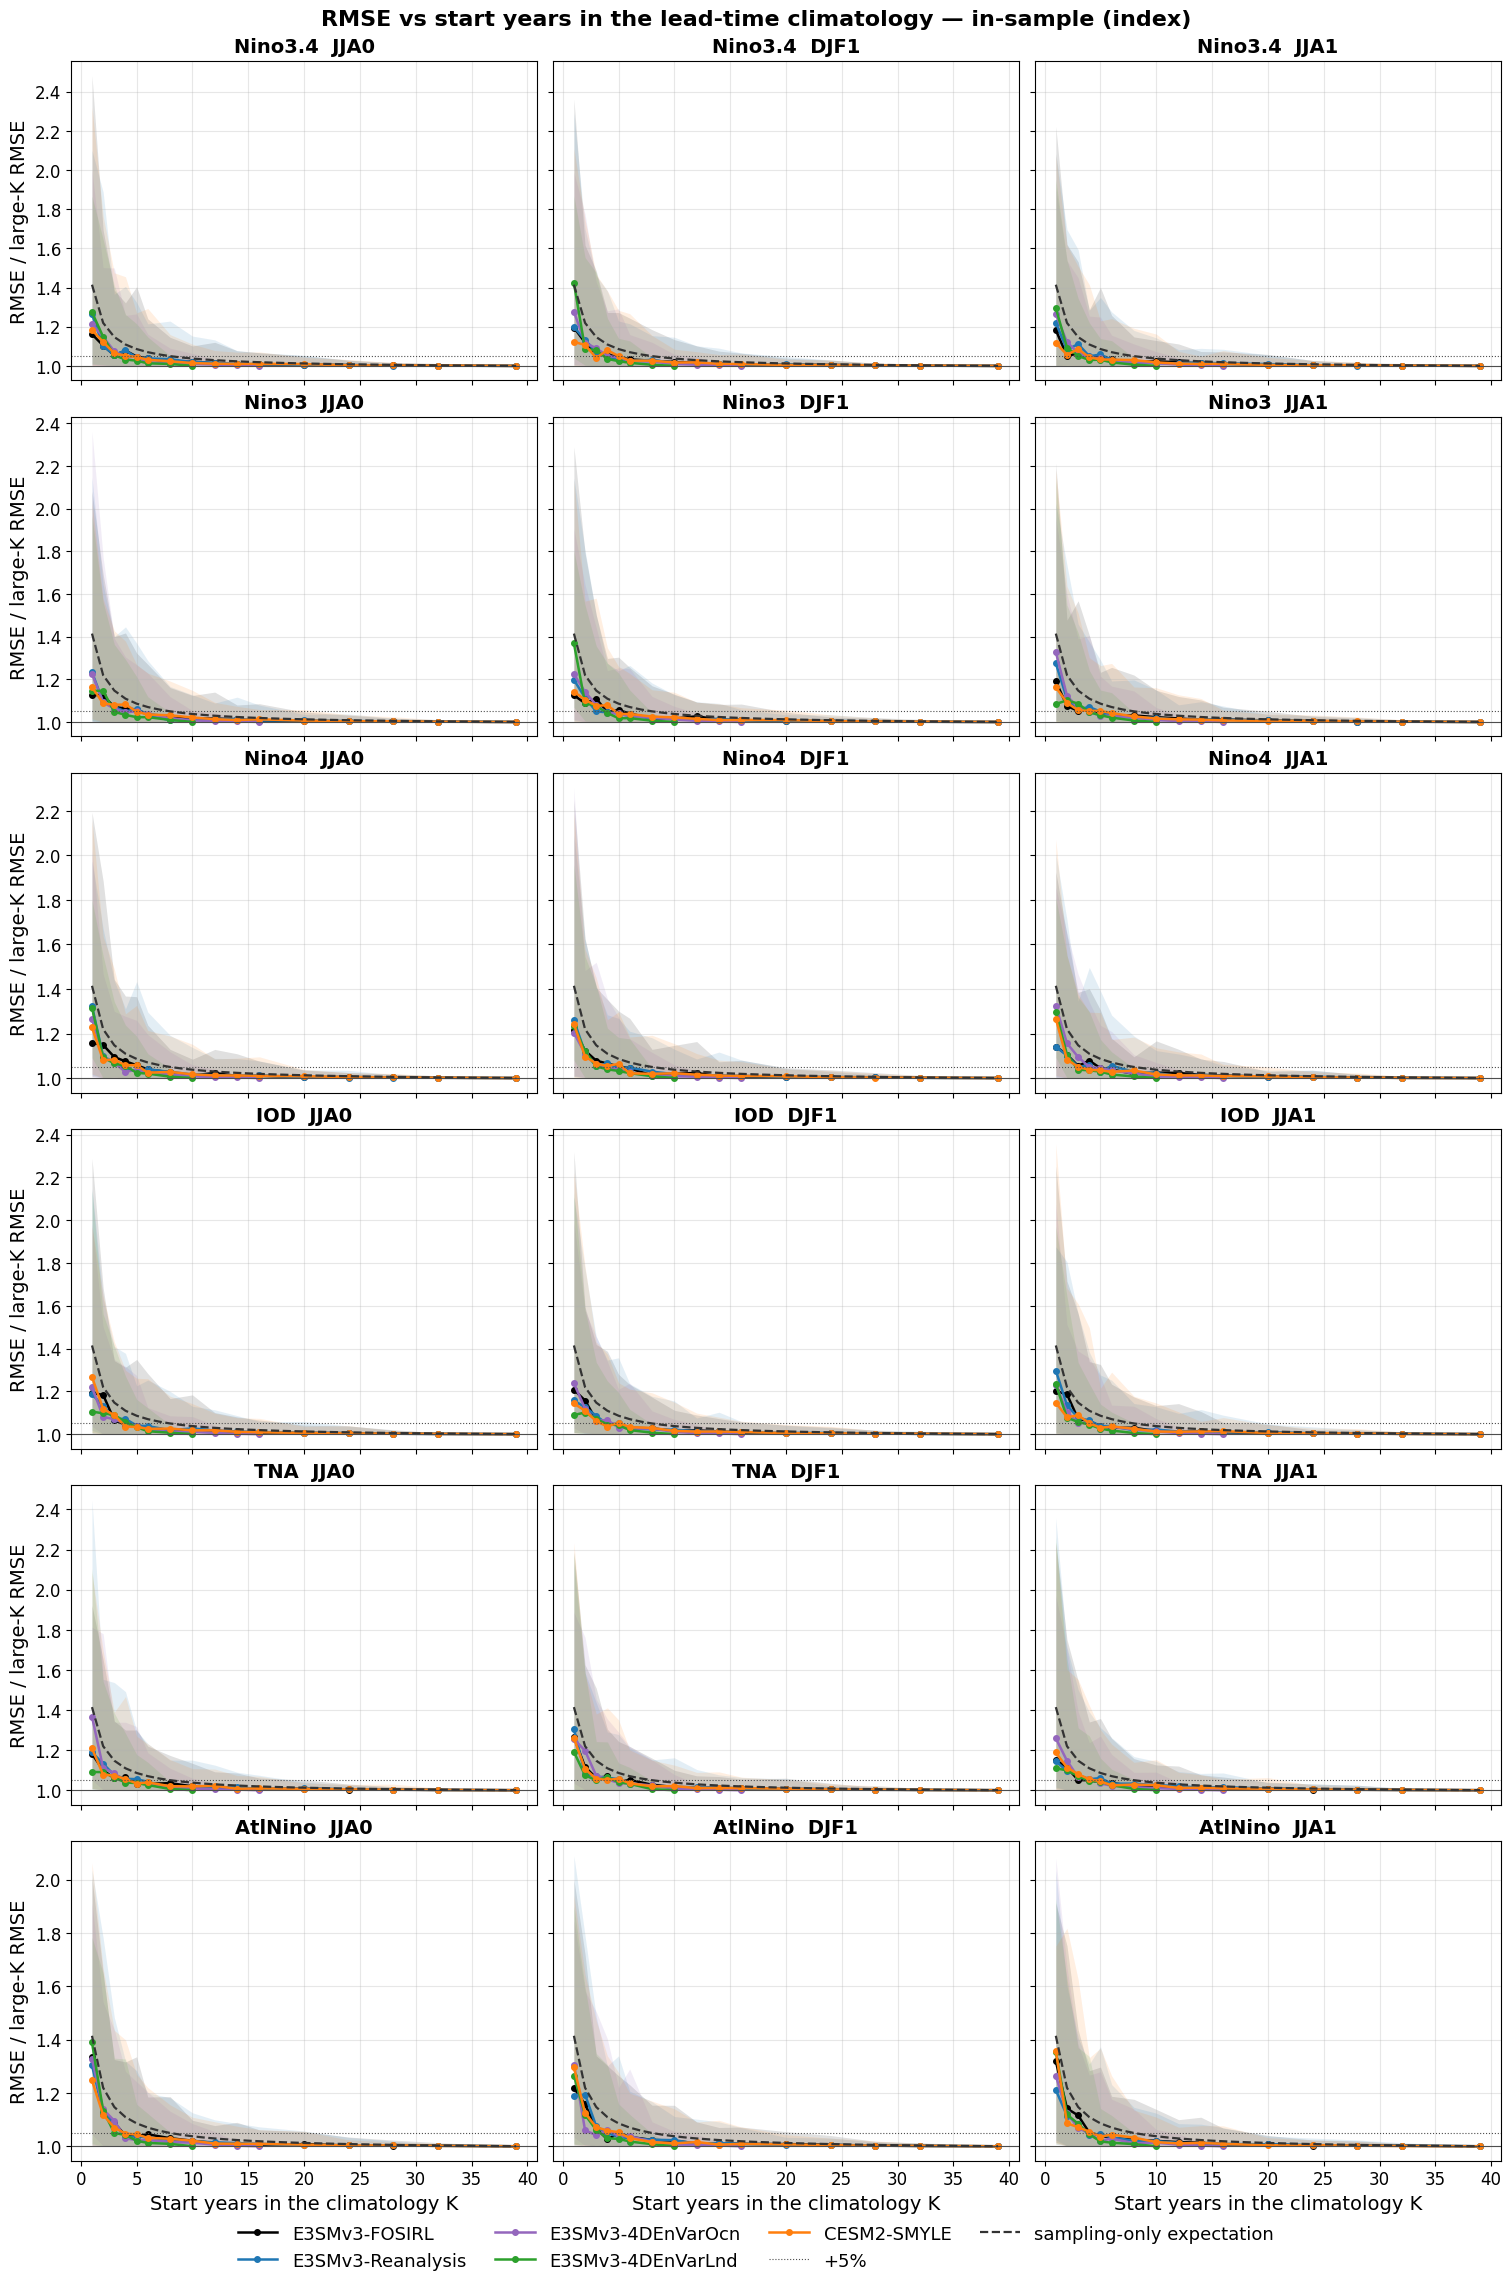

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_cross-validated_sst.png


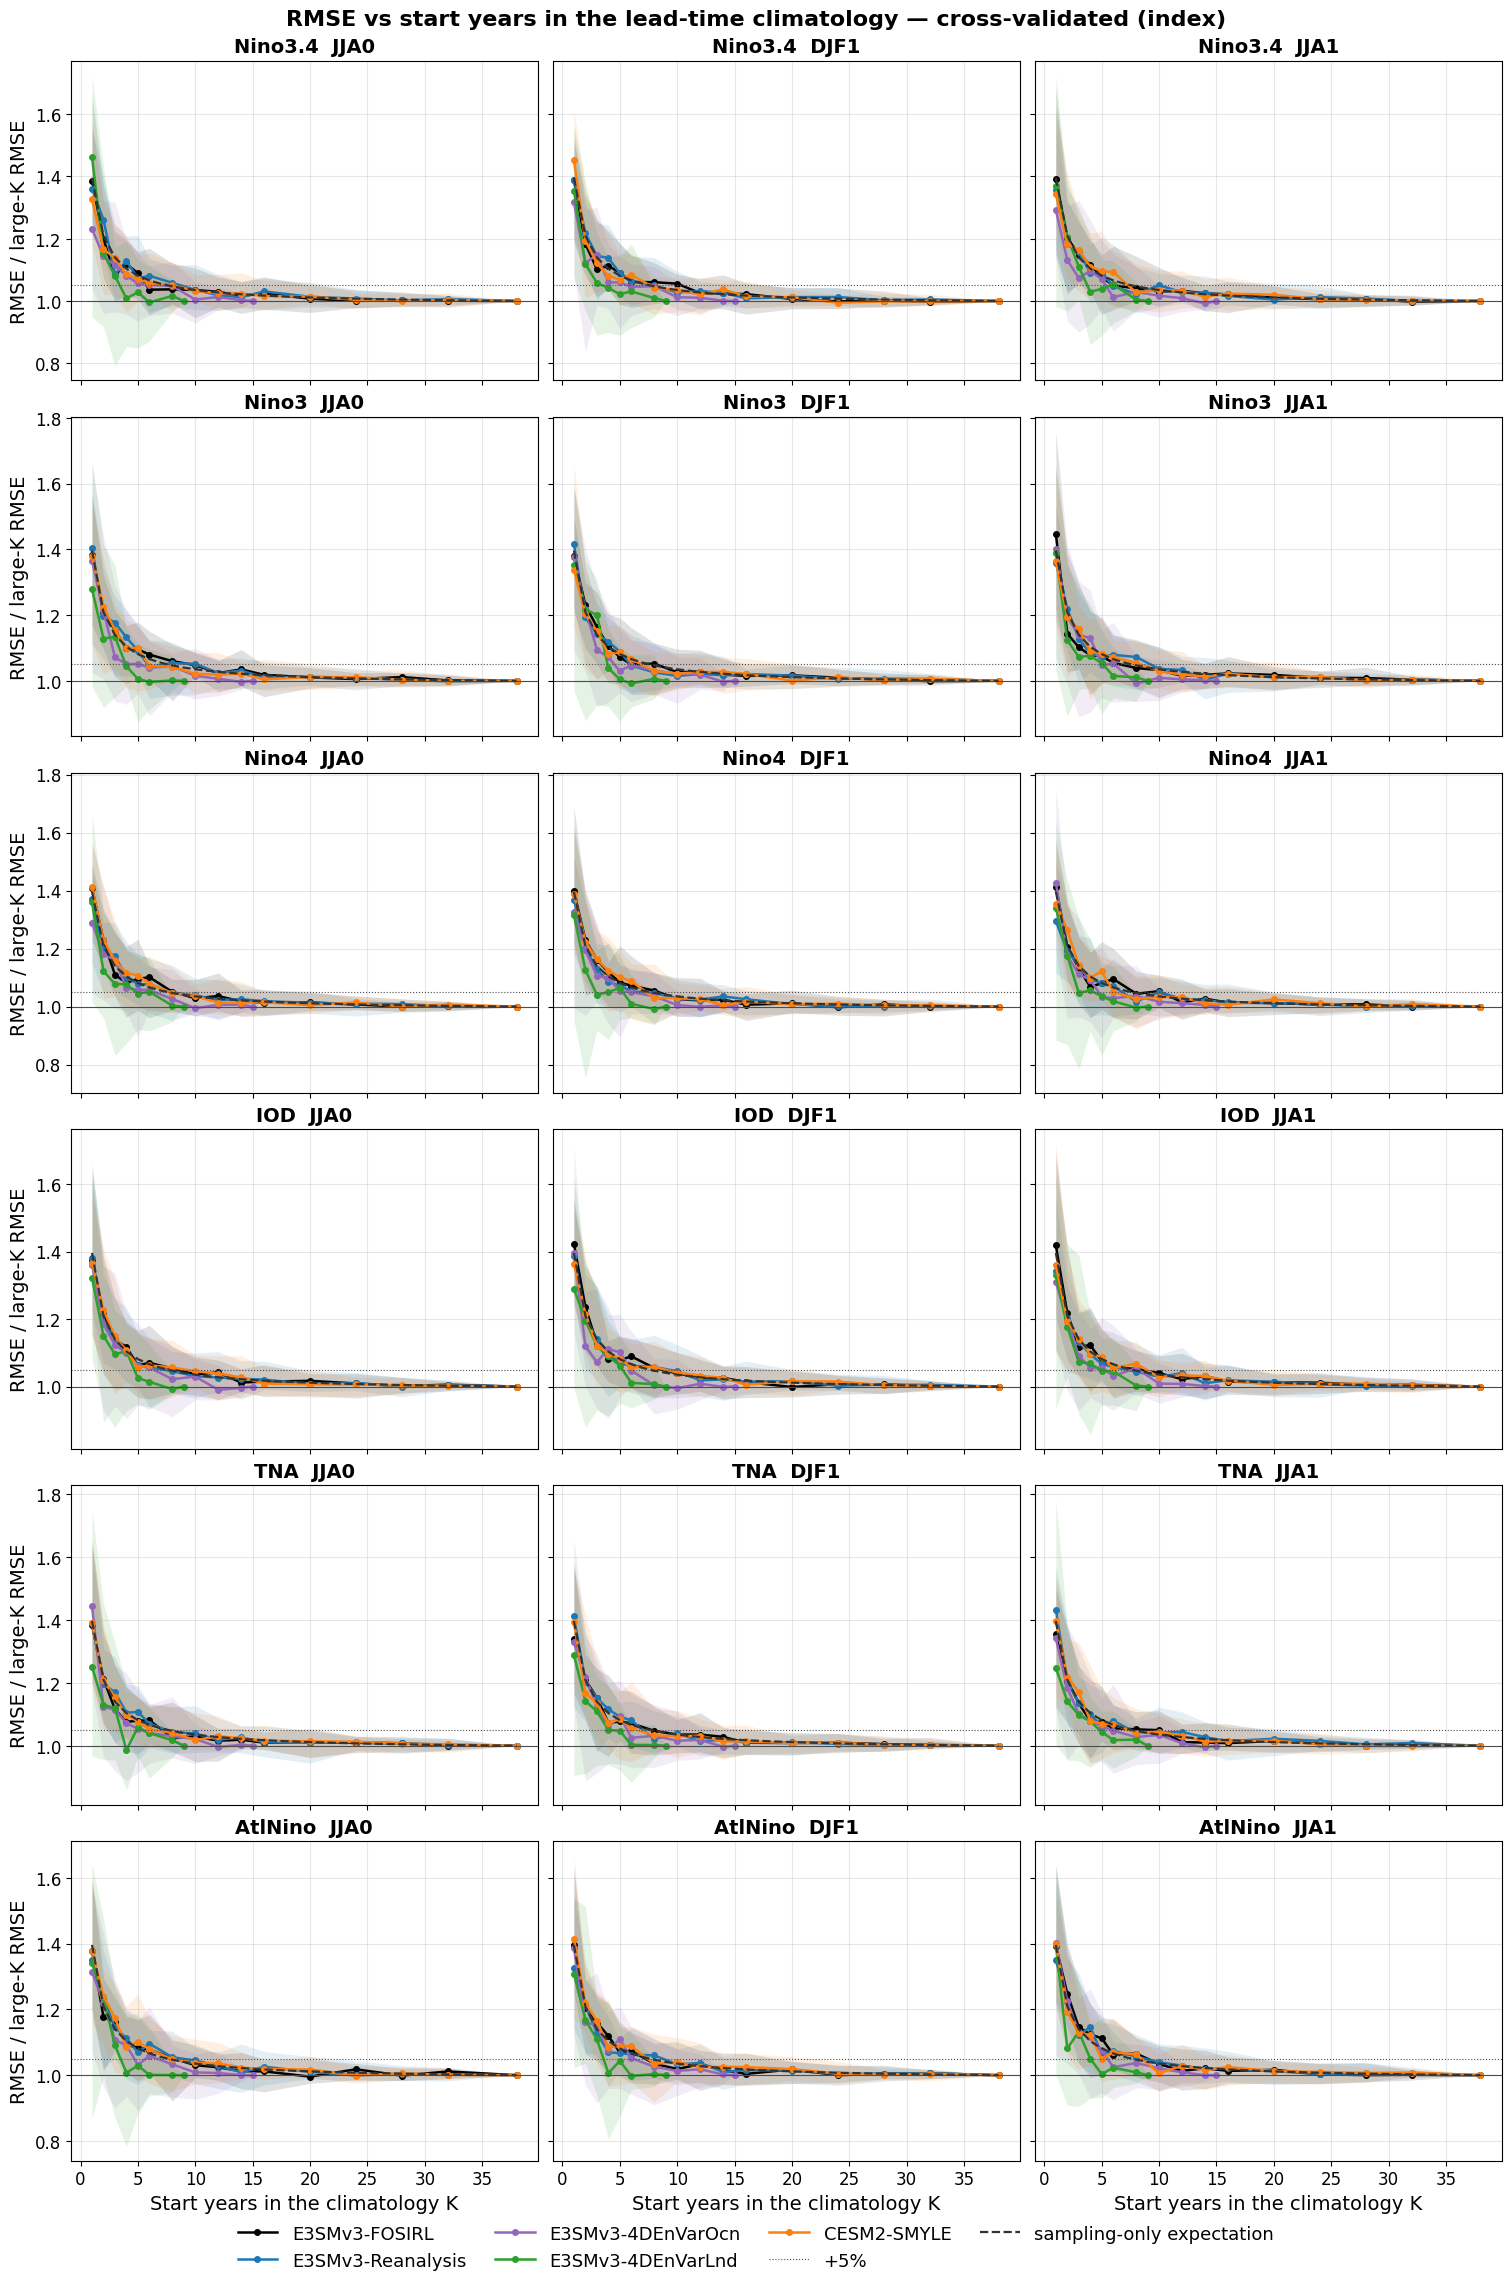

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_error_sst.png


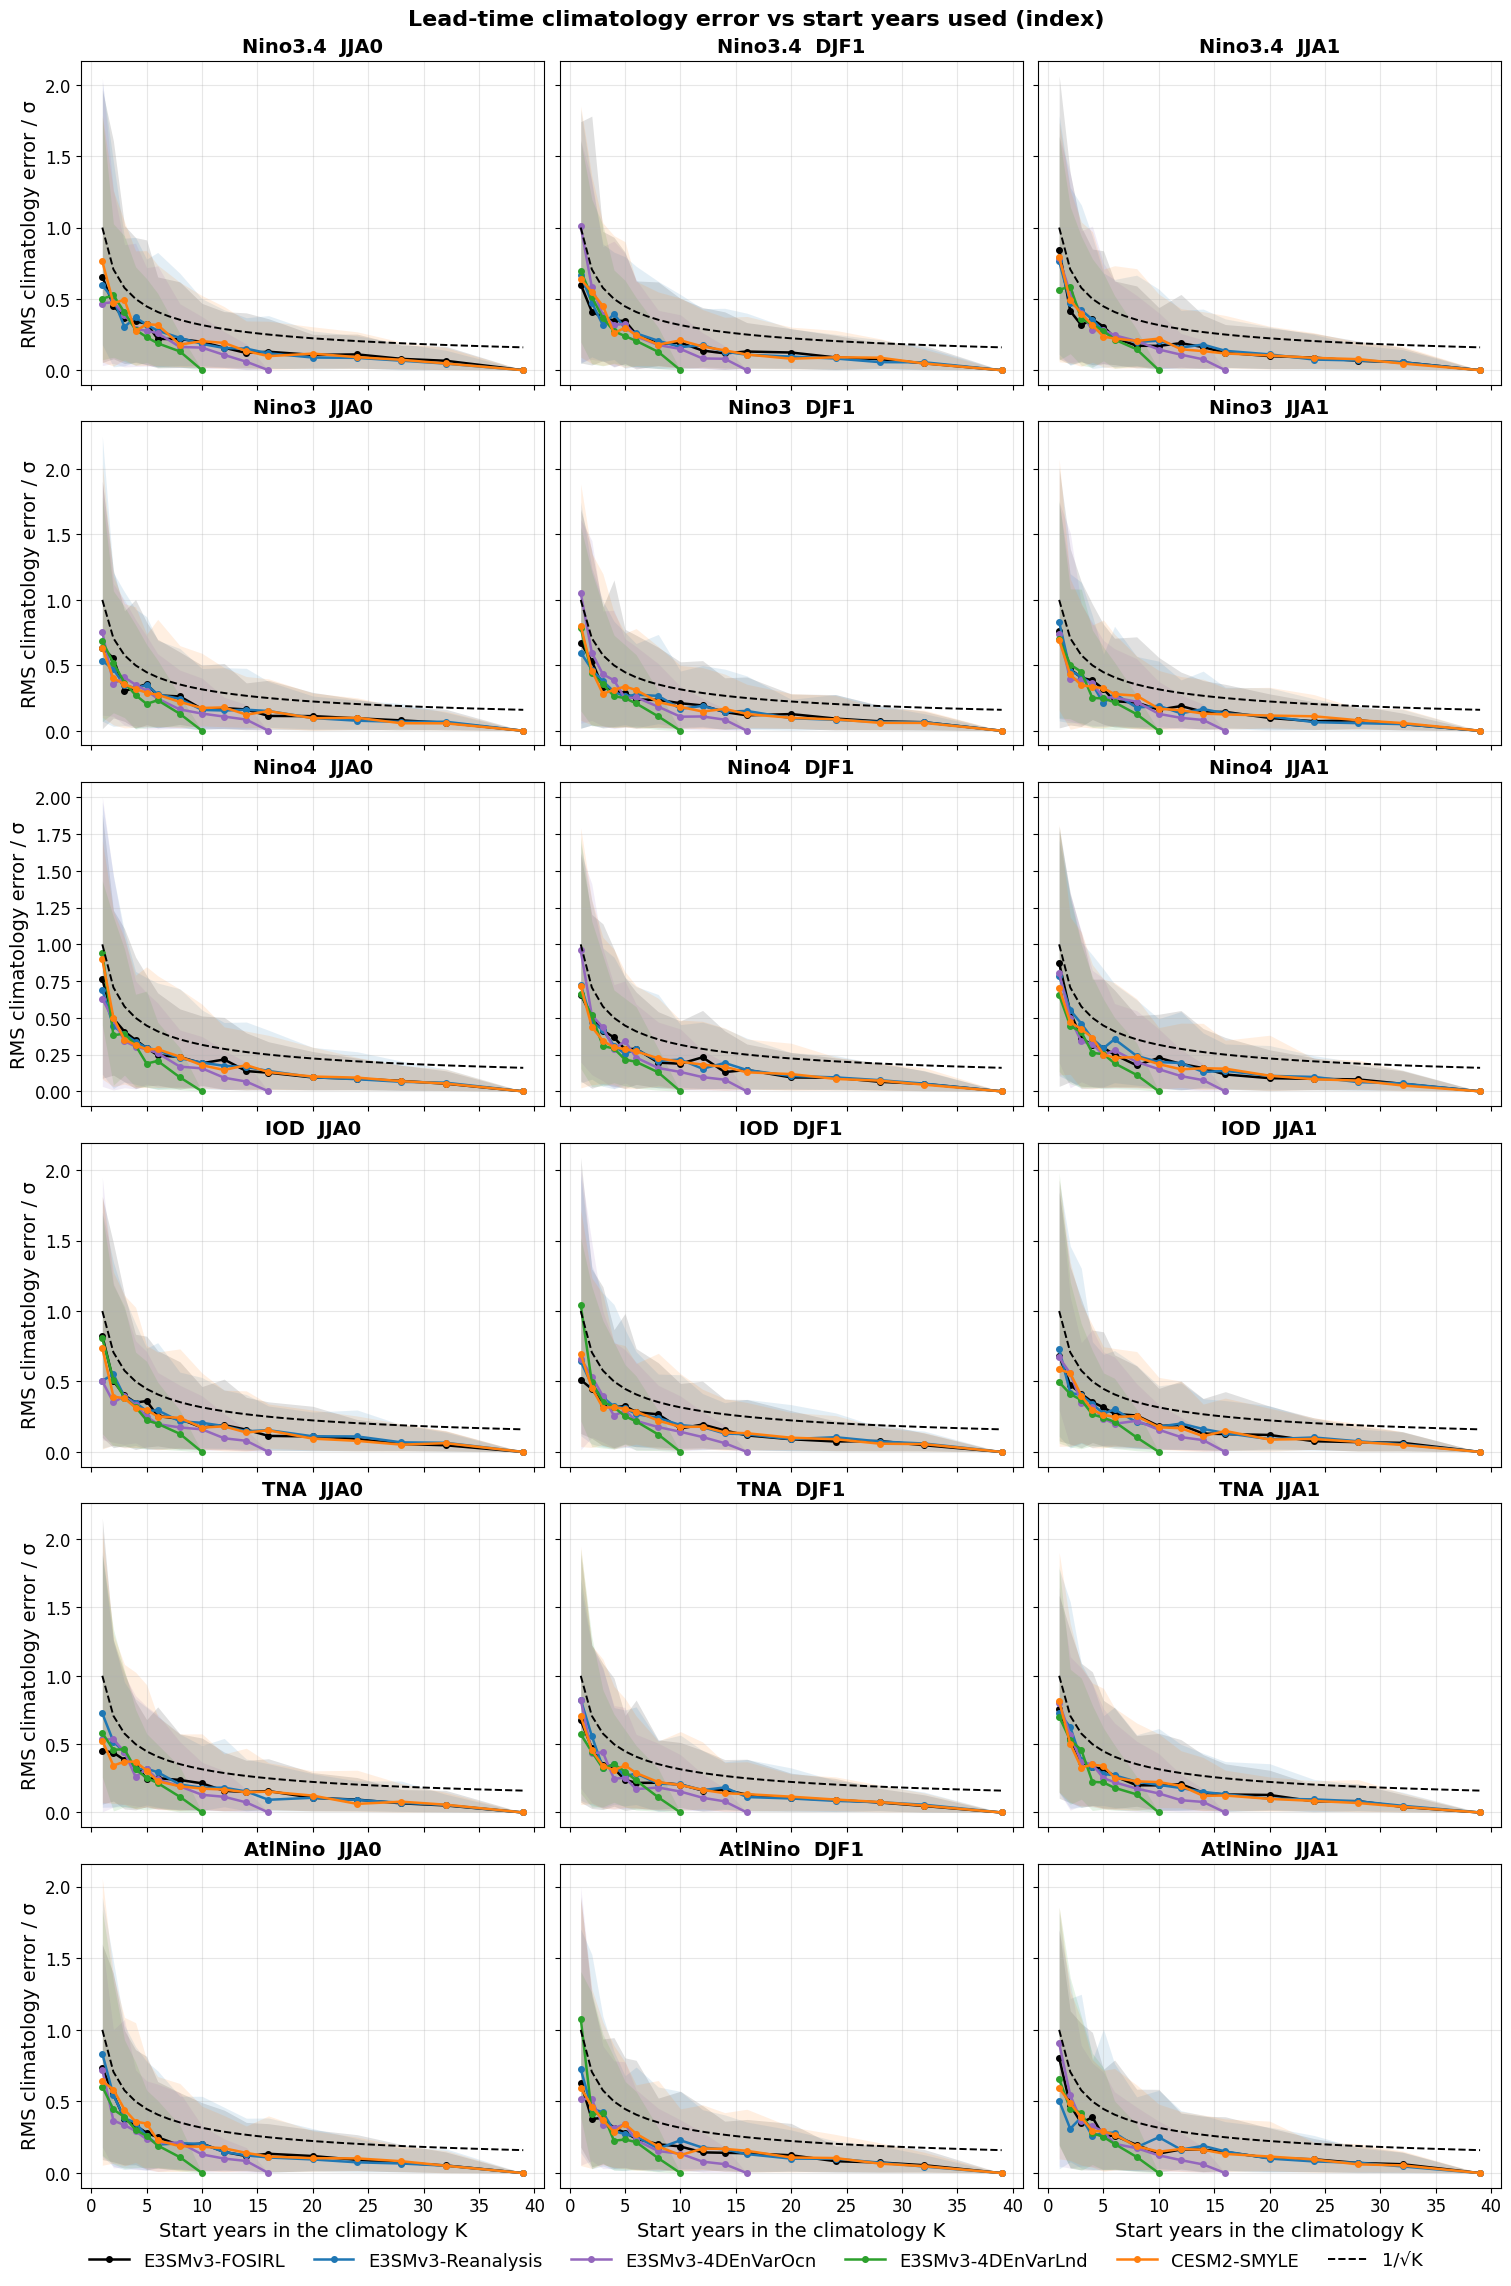

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_in-sample_lnd.png


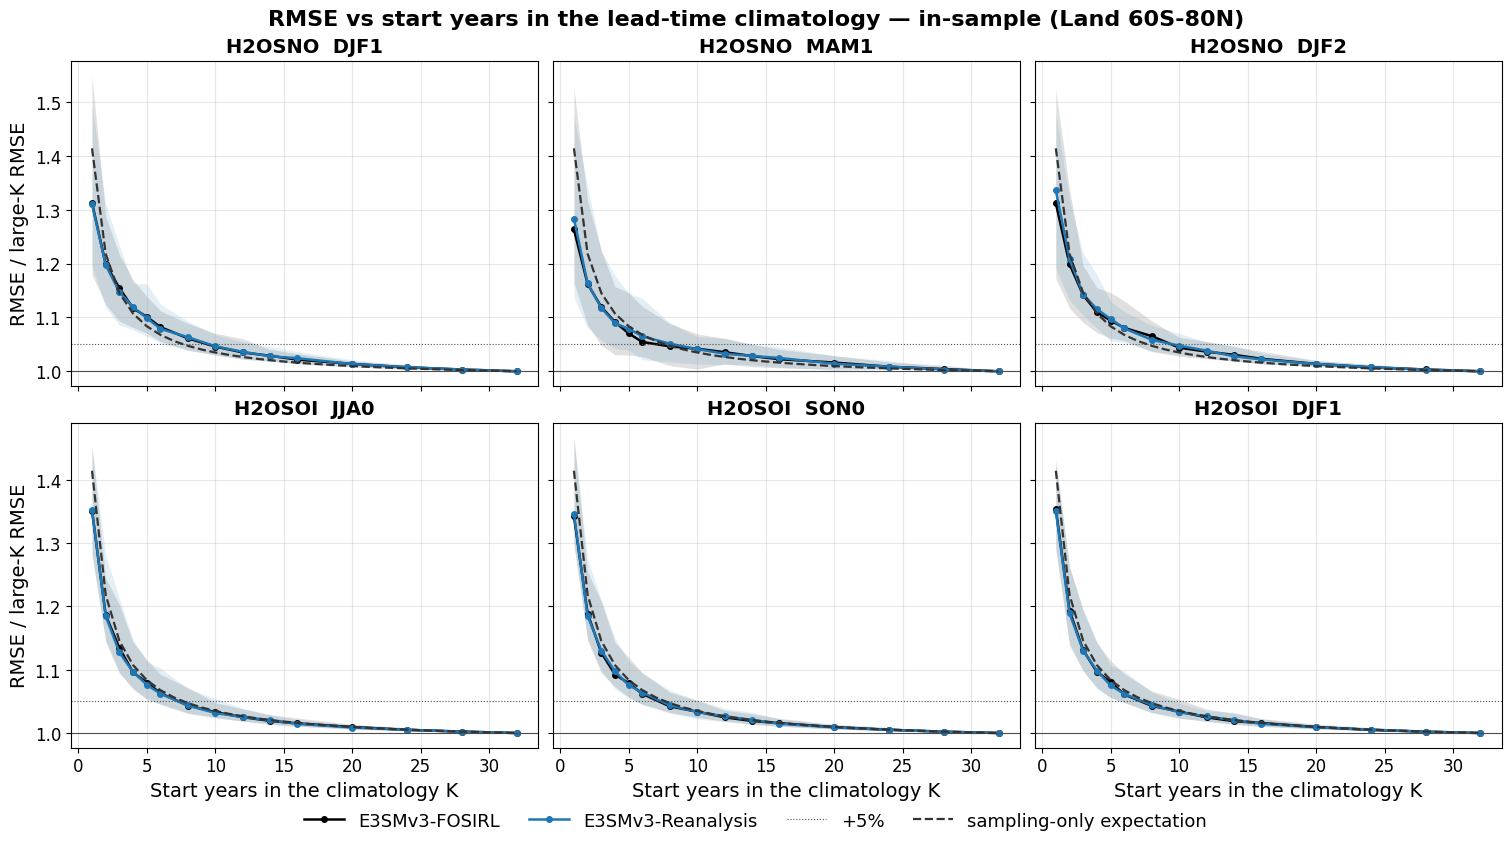

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_cross-validated_lnd.png


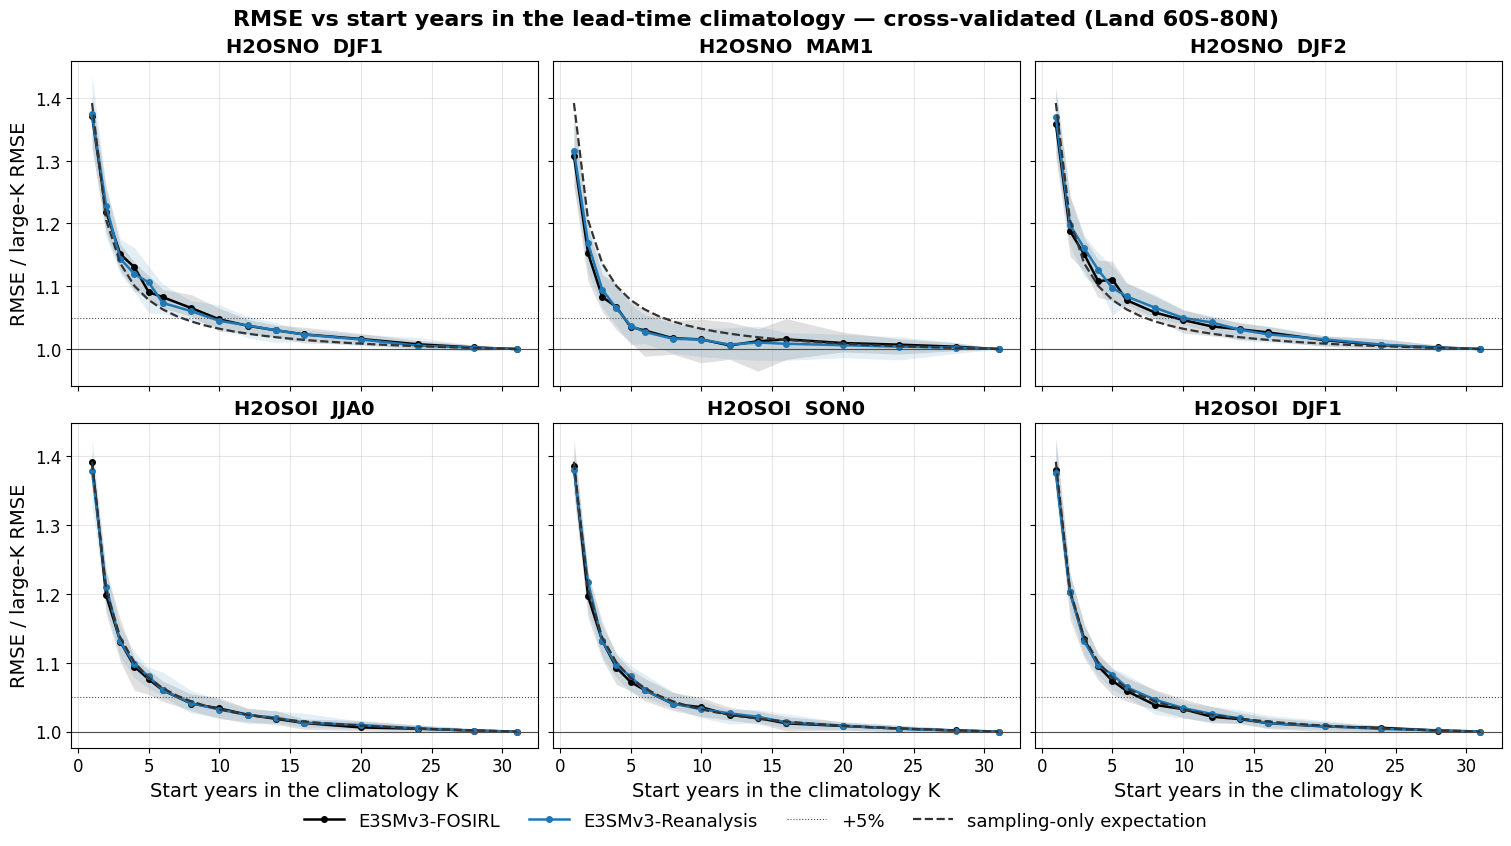

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_error_lnd.png


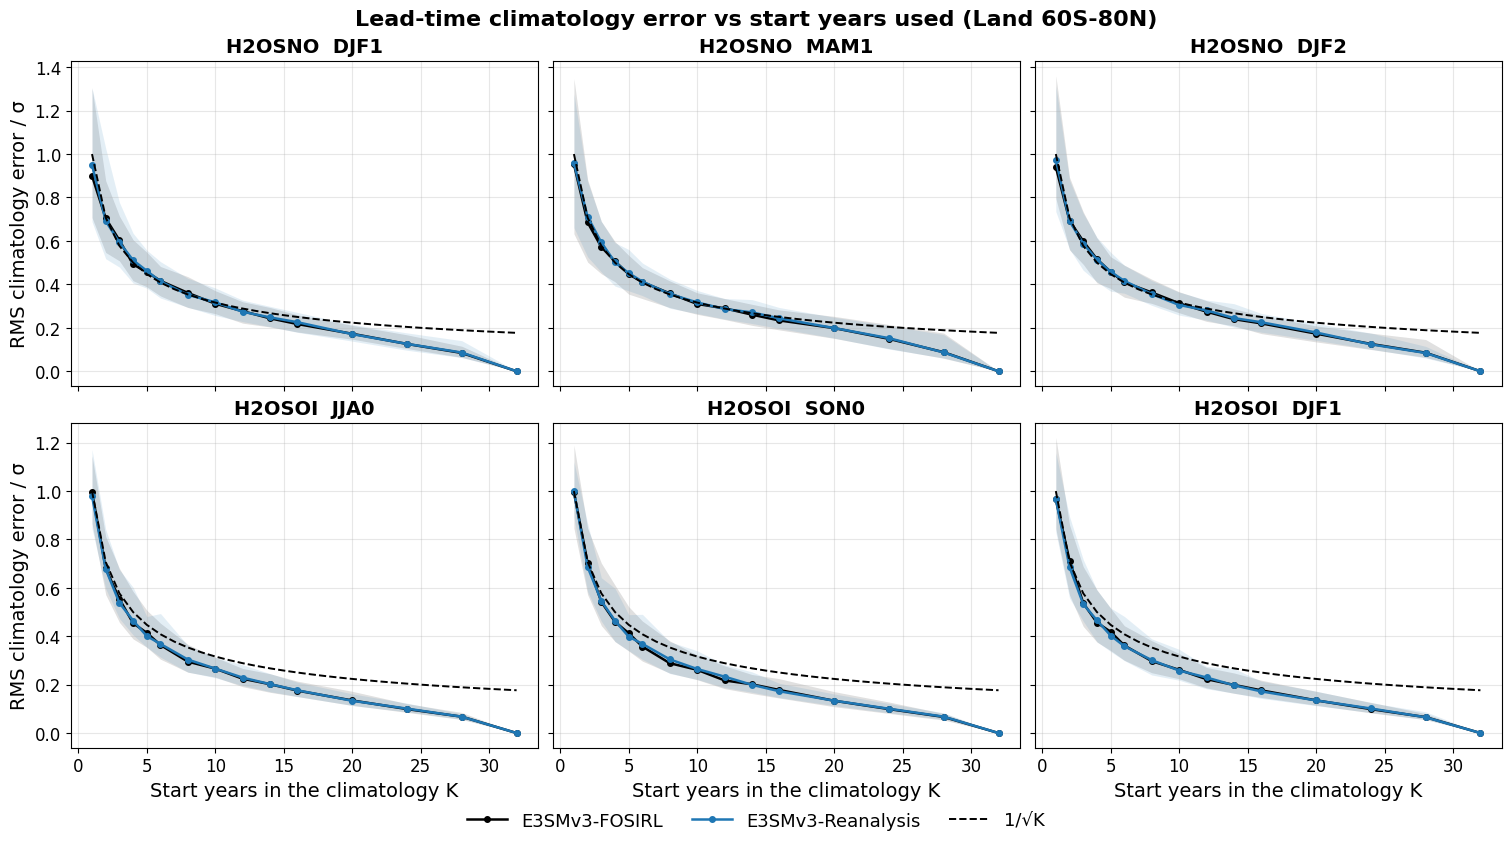

In [8]:
rows = []
for group, fields in DATA.items():
    for field, experiments in fields.items():
        for key, d in experiments.items():
            members = year_members(d["members"])
            n_max = members.sizes["Y"]
            # Cross-validated draws hold one climatology per scored year, so fewer draws suffice.
            for variant, k_max, draw_fn, draws in (
                    ("in-sample", n_max, sss.random_subsets, N_DRAWS),
                    ("cross-validated", n_max - 1, sss.cross_validated_subsets, max(N_DRAWS // 4, 10))):
                for k in sorted({k for k in K_GRID if k <= k_max} | {k_max}):
                    weights = draw_fn(n_max, k, draws, rng)
                    scores = sss.climatology_subset_scores(members, d["obs"], weights, reduce=REDUCE[group])
                    rows += summarize(scores, ["rmse", "nrmse", "clim_error", "bias"], group=group, field=field,
                                      experiment=key, variant=variant, clim_years=k, record_years=n_max)
        print(f"Part 3 done: {group} {field}")
part3 = pd.DataFrame(rows)

# Normalize RMSE by its large-K reference: in-sample K = N (the workflow), cross-validated K = N - 1.
keys = ["group", "field", "experiment", "region", "lead", "variant"]
largest = part3.groupby(keys).clim_years.transform("max")
ref = (part3[(part3.metric == "rmse") & (part3.clim_years == largest)]
       .set_index(keys)["median"].rename("rmse_large_k"))
part3 = part3.join(ref, on=keys)
ratio = part3[part3.metric == "rmse"].copy()
for col in ("p05", "median", "p95"):
    ratio[col] = ratio[col] / ratio["rmse_large_k"]
ratio["metric"] = "rmse_ratio"
part3 = pd.concat([part3, ratio], ignore_index=True)
part3.to_csv(TABLE_DIR / f"sample_size_part3_climatology_init{INIT_MONTH:02d}.csv", index=False)


def tolerance_lines(ax, group, field, lead, panel):
    ax.axhline(1.0, color="0.3", lw=0.8)
    ax.axhline(1 + CLIM_TOLERANCE, color="0.3", lw=0.8, ls=":", label=f"+{CLIM_TOLERANCE:.0%}")
    n = int(panel.record_years.max())
    k = np.arange(1, int(panel.clim_years.max()) + 1, dtype=float)
    if (panel.variant == "in-sample").all():
        expected = np.sqrt((1 + 1 / k - 2 / n) / (1 - 1 / n))
    else:
        expected = np.sqrt((1 + 1 / k) / (1 + 1 / (n - 1)))
    ax.plot(k, expected, color="0.2", ls="--", lw=1.6, zorder=5, label="sampling-only expectation")


def sampling_guide(ax, group, field, lead, panel):
    k = np.arange(1, int(panel.clim_years.max()) + 1)
    ax.plot(k, 1 / np.sqrt(k), "k--", lw=1.4, zorder=5, label="1/√K")


for group in DATA:
    for variant in ("in-sample", "cross-validated"):
        plot_curves(part3, group, "clim_years", "RMSE / large-K RMSE",
                    f"RMSE vs start years in the lead-time climatology — {variant} ({PLOT_REGION[group]})",
                    f"fig_sample_size_climatology_rmse_{variant}_{group}.png", metric="rmse_ratio",
                    variant=variant, extra=tolerance_lines)
    plot_curves(part3, group, "clim_years", "RMS climatology error / σ",
                f"Lead-time climatology error vs start years used ({PLOT_REGION[group]})",
                f"fig_sample_size_climatology_error_{group}.png", metric="clim_error",
                variant="in-sample", extra=sampling_guide)

In [9]:
# Smallest number of climatology start years from which RMSE is stable (see CLIM_TOLERANCE).
rows = []
for (group, field, key, region, lead, variant), curve in part3[part3.metric == "rmse_ratio"].groupby(
        ["group", "field", "experiment", "region", "lead", "variant"]):
    curve = curve.sort_values("clim_years")
    k_min = sss.smallest_stable_size(curve.clim_years.tolist(), curve["median"], curve["p95"], 1.0, CLIM_TOLERANCE)
    rows.append(dict(group=group, field=field, experiment=key, region=region, lead=lead, variant=variant,
                     record_years=int(curve.record_years.iloc[0]), min_clim_years=k_min))
min_k = pd.DataFrame(rows)
min_k.to_csv(TABLE_DIR / f"sample_size_part3_min_clim_years_init{INIT_MONTH:02d}.csv", index=False)
print("Smallest stable K (worst lead shown; blank = not reached within the record).\n"
      "Short records (e.g. 4DEnVarLnd) are judged against their own, short, large-K value.")
(min_k[min_k.region.isin(PLOT_REGION.values())]
 .assign(min_clim_years=lambda t: t.min_clim_years.astype("float"))
 .pivot_table(index=["group", "field", "experiment"], columns="variant", values="min_clim_years", aggfunc="max"))

Smallest stable K (worst lead shown; blank = not reached within the record).
Short records (e.g. 4DEnVarLnd) are judged against their own, short, large-K value.


variant                        cross-validated  in-sample
group field   experiment                                 
atm   PRECT   CESM-SMYLE                   8.0        8.0
              E3SM-4DEnVarLnd              5.0        6.0
              E3SM-4DEnVarOcn              6.0        8.0
              E3SM-FOSIRL                  8.0        8.0
              E3SM-Reanalysis              8.0        8.0
      PSL     CESM-SMYLE                   8.0       10.0
              E3SM-4DEnVarLnd              6.0        6.0
              E3SM-4DEnVarOcn              6.0        8.0
              E3SM-FOSIRL                  8.0       10.0
              E3SM-Reanalysis              8.0       10.0
      TREFHT  CESM-SMYLE                  10.0        8.0
              E3SM-4DEnVarLnd              5.0        6.0
              E3SM-4DEnVarOcn              6.0        8.0
              E3SM-FOSIRL                 10.0        8.0
              E3SM-Reanalysis             10.0        8.0
      TS      CESM-SMYLE                  10.0        8.0
              E3SM-4DEnVarLnd              5.0        6.0
              E3SM-4DEnVarOcn              6.0        8.0
              E3SM-FOSIRL                  8.0       10.0
              E3SM-Reanalysis              8.0       10.0
lnd   H2OSNO  E3SM-FOSIRL                 10.0       10.0
              E3SM-Reanalysis             10.0       10.0
      H2OSOI  E3SM-FOSIRL                  8.0        8.0
              E3SM-Reanalysis              8.0        8.0
sst   AtlNino CESM-SMYLE                  12.0       14.0
              E3SM-4DEnVarLnd              8.0        8.0
              E3SM-4DEnVarOcn             10.0       10.0
              E3SM-FOSIRL                 12.0       16.0
              E3SM-Reanalysis             12.0       16.0
      IOD     CESM-SMYLE                  14.0       16.0
              E3SM-4DEnVarLnd              8.0        8.0
              E3SM-4DEnVarOcn             10.0       10.0
              E3SM-FOSIRL                 12.0       16.0
              E3SM-Reanalysis             14.0       16.0
      Nino3   CESM-SMYLE                  14.0       16.0
              E3SM-4DEnVarLnd              8.0        8.0
              E3SM-4DEnVarOcn             10.0       10.0
              E3SM-FOSIRL                 12.0       16.0
              E3SM-Reanalysis             12.0       16.0
      Nino3.4 CESM-SMYLE                  12.0       14.0
              E3SM-4DEnVarLnd              8.0        8.0
              E3SM-4DEnVarOcn             10.0       10.0
              E3SM-FOSIRL                 12.0       14.0
              E3SM-Reanalysis             12.0       16.0
      Nino4   CESM-SMYLE                  12.0       16.0
              E3SM-4DEnVarLnd              8.0        8.0
              E3SM-4DEnVarOcn             10.0       10.0
              E3SM-FOSIRL                 14.0       16.0
              E3SM-Reanalysis             12.0       16.0
      TNA     CESM-SMYLE                  12.0       16.0
              E3SM-4DEnVarLnd              8.0        8.0
              E3SM-4DEnVarOcn             12.0       10.0
              E3SM-FOSIRL                 14.0       14.0
              E3SM-Reanalysis             14.0       16.0